In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading, cleaning, floor-plan constants and the time layer (service day, turn gaps,
# occupancy) all live in artemis.py so this notebook and any report generator share one
# pipeline. Editing a cleaning rule there changes it everywhere.
import sys
sys.path.insert(0, '..')  # weather.py lives at the repo root
import artemis

In [2]:
# All the cleaning that used to live in this cell now lives in artemis.load_orders() --
# duplicate-chunk removal, numeric coercion, Amount > 0, the implausible-guest-count cut and
# the BD4 exclusion, unchanged. See artemis.py for the reasoning behind each rule.
#
# Two things are new. Full datetimes are preserved as Opened_DT / Closed_DT / Paid_DT (the
# display cells below overwrite Opened/Closed with time-only strings, which used to destroy
# the date and made any time-of-night analysis impossible). And every order gets a
# Service_Date: a Friday that runs to 1:30am now counts as Friday rather than spilling into
# Saturday.
#
# With no argument, load_orders() reads every Toast pull in data/exports/ merged into one
# continuous dataset, rebuilding that merge first if a new export has appeared. Pull a fresh
# export from Toast, drop it in that folder, re-run this notebook, and the whole analysis
# extends -- no path to edit here. merge_exports.py has the details of how overlapping pulls
# and after-the-fact amendments are reconciled.
df = artemis.load_orders()
df.head(10)

Exact duplicate rows from overlapping export chunks: 0
Excluded 6 row(s) with implausible guest counts (> 20).
Excluded 83 row(s) from BD4 (retired table, no longer in service).
6 order(s) have no duration and are excluded from the turn-gap and occupancy layers.
Loaded 19353 orders, 455 service days (2025-04-25 to 2026-09-29).


,Opened,# of Guests,Table,Discount Amount,Amount,Tip,Gratuity,Closed,Tax,Total,...,Capacity_Min,Capacity_Max,Seating_Unit,Unit_Capacity,Likely_Combined_Booking,Exceeds_Solo_Capacity,Order_Type,Service_Date,Service_DOW,Clock_Minutes
0,04/25/25 05:29 PM,3,O9,40.66,40.66,40.0,0.0,04/25/25 06:57 PM,3.49,84.15,...,2.0,2.0,O9+O10,4.0,False,True,Seated,2025-04-25,Friday,1049.0
1,04/25/25 05:31 PM,4,E5,110.28,110.42,0.0,0.0,04/25/25 08:00 PM,9.49,119.91,...,NaN,NaN,NaN,NaN,False,False,Seated,2025-04-25,Friday,1051.0
2,04/25/25 05:38 PM,2,E2,38.20,38.24,0.0,0.0,04/25/25 07:04 PM,3.29,41.53,...,2.0,2.0,E 2+2 pair,4.0,False,False,Seated,2025-04-25,Friday,1058.0
3,04/25/25 05:39 PM,3,O6,41.40,41.34,30.0,0.0,04/25/25 11:55 PM,3.58,74.92,...,2.0,2.0,O6,2.0,True,True,Seated,2025-04-25,Friday,1059.0
4,04/25/25 06:07 PM,4,O5,77.96,78.06,0.0,0.0,04/25/25 11:53 PM,6.70,84.76,...,2.0,2.0,O4+O5,4.0,False,True,Seated,2025-04-25,Friday,1087.0
5,04/25/25 06:08 PM,1,B9,21.98,21.99,0.0,0.0,04/25/25 07:57 PM,1.28,23.27,...,1.0,1.0,B9,1.0,False,False,Seated,2025-04-25,Friday,1088.0
6,04/25/25 06:12 PM,2,O10,89.20,57.84,0.0,0.0,04/25/25 08:48 PM,5.01,62.85,...,2.0,2.0,O9+O10,4.0,False,False,Seated,2025-04-25,Friday,1092.0
7,04/25/25 06:29 PM,2,BD1,139.58,139.53,60.0,0.0,04/25/25 10:11 PM,12.04,211.57,...,3.0,4.0,BD 6-top banquette,6.0,False,False,Seated,2025-04-25,Friday,1109.0
8,04/25/25 06:33 PM,1,B7,0.00,29.44,18.0,0.0,04/25/25 11:47 PM,2.56,50.00,...,1.0,1.0,B7,1.0,False,False,Seated,2025-04-25,Friday,1113.0
9,04/25/25 06:35 PM,1,B10,20.58,20.58,10.0,0.0,04/25/25 11:47 PM,1.77,32.35,...,1.0,1.0,B10,1.0,False,False,Seated,2025-04-25,Friday,1115.0


In [3]:
df['Amount'].sort_values(ascending=False)


10537    5127.09
14036    4704.00
6628     2900.00
17636    2432.93
2819     2400.00
          ...   
7719        0.01
3303        0.01
3311        0.01
3337        0.01
16695       0.01
Name: Amount, Length: 19353, dtype: float64

In [4]:
# get_section() moved to artemis.py; df['Section'] is already assigned by load_orders().
#
# What's new here: every order is now labelled Seated / Event-Catering / To-Go. Previously
# anything without a table fell through the Duration >= 15 floor below and disappeared from the
# analysis entirely -- that was ~$104K of real revenue vanishing silently. These aren't seated
# tables so they still don't belong in per-seat VPCPM/TPCPM, but they shouldn't be invisible.
#
# The split is by check size, not time of day: untabled orders happen across the whole operating
# day, but a $2,200 untabled check is a catering booking whatever hour it was rung in, and a $40
# one is a pickup. Durations on untabled rows are meaningless (they range up to 18 days) because
# nobody was sitting anywhere.
order_types = (
    df.groupby('Order_Type')
      .agg(**{'Orders': ('Amount', 'count'), 'Revenue ($)': ('Amount', 'sum')})
)
order_types['Revenue Share %'] = (100 * order_types['Revenue ($)'] / order_types['Revenue ($)'].sum()).round(1)
order_types.round(2)

,Orders,Revenue ($),Revenue Share %
Order_Type,,,
Event-Catering,182,191935.71,8.5
Seated,18243,2001609.49,88.5
To-Go,928,67512.30,3.0


In [5]:
# Duration now comes from artemis.load_orders() -- it parses Toast's own
# 'Duration (Opened to Paid)' rather than differencing Closed - Opened, since Closed frequently
# reflects a late/batch POS close-out rather than actual guest departure.
#
# How much does the Duration >= 15min floor censor each section? Bar is walk-up/quick-turnover,
# so this filter is expected to drop a disproportionate share of Bar rows -- worth knowing before
# trusting any section's stats, especially Bar's (see the context-only summary at the end).
# Unknown/To-Go loses two thirds of its rows here, which is exactly the revenue the Order_Type
# split above now keeps visible.
df, drop_summary = artemis.apply_duration_floor(df)
drop_summary

,Before,After,Dropped,Drop %
Section,,,,
Unknown/To-Go,1110,324,786,70.8
Bar,7769,6316,1453,18.7
Open Lounge,7259,7167,92,1.3
Black Duck,1664,1647,17,1.0
Evangeline,1551,1538,13,0.8


In [6]:
# Display-only formatting. Overwriting Opened/Closed with time-only strings is now safe:
# the real timestamps live on in Opened_DT / Closed_DT / Paid_DT, and everything time-based
# reads those instead.
df.insert(0, 'Date', df['Opened_DT'].dt.strftime('%m/%d/%y'))
df['Opened'] = df['Opened_DT'].dt.strftime('%I:%M %p')
df['Closed'] = df['Closed_DT'].dt.strftime('%I:%M %p')

df.head(10)

,Date,Opened,# of Guests,Table,Discount Amount,Amount,Tip,Gratuity,Closed,Tax,...,Capacity_Min,Capacity_Max,Seating_Unit,Unit_Capacity,Likely_Combined_Booking,Exceeds_Solo_Capacity,Order_Type,Service_Date,Service_DOW,Clock_Minutes
0,04/25/25,05:29 PM,3,O9,40.66,40.66,40.0,0.0,06:57 PM,3.49,...,2.0,2.0,O9+O10,4.0,False,True,Seated,2025-04-25,Friday,1049.0
1,04/25/25,05:31 PM,4,E5,110.28,110.42,0.0,0.0,08:00 PM,9.49,...,NaN,NaN,NaN,NaN,False,False,Seated,2025-04-25,Friday,1051.0
2,04/25/25,05:38 PM,2,E2,38.20,38.24,0.0,0.0,07:04 PM,3.29,...,2.0,2.0,E 2+2 pair,4.0,False,False,Seated,2025-04-25,Friday,1058.0
3,04/25/25,05:39 PM,3,O6,41.40,41.34,30.0,0.0,11:55 PM,3.58,...,2.0,2.0,O6,2.0,True,True,Seated,2025-04-25,Friday,1059.0
4,04/25/25,06:07 PM,4,O5,77.96,78.06,0.0,0.0,11:53 PM,6.70,...,2.0,2.0,O4+O5,4.0,False,True,Seated,2025-04-25,Friday,1087.0
5,04/25/25,06:08 PM,1,B9,21.98,21.99,0.0,0.0,07:57 PM,1.28,...,1.0,1.0,B9,1.0,False,False,Seated,2025-04-25,Friday,1088.0
6,04/25/25,06:12 PM,2,O10,89.20,57.84,0.0,0.0,08:48 PM,5.01,...,2.0,2.0,O9+O10,4.0,False,False,Seated,2025-04-25,Friday,1092.0
7,04/25/25,06:29 PM,2,BD1,139.58,139.53,60.0,0.0,10:11 PM,12.04,...,3.0,4.0,BD 6-top banquette,6.0,False,False,Seated,2025-04-25,Friday,1109.0
8,04/25/25,06:33 PM,1,B7,0.00,29.44,18.0,0.0,11:47 PM,2.56,...,1.0,1.0,B7,1.0,False,False,Seated,2025-04-25,Friday,1113.0
9,04/25/25,06:35 PM,1,B10,20.58,20.58,10.0,0.0,11:47 PM,1.77,...,1.0,1.0,B10,1.0,False,False,Seated,2025-04-25,Friday,1115.0


# Value per Person per 15 Minutes


In [7]:
# VPCPM is stored on the raw dollar scale for display, plus a log-scale column (LogVPCPM) used
# for the mean/variance math -- $/guest/15min is right-skewed, and a log-normal assumption is
# what makes mean/SEM/shrinkage math valid. Aggregates below are always back-transformed to
# dollars via exp(mean of logs) -- the geometric mean -- rather than shown in raw log units.
df['VPCPM'] = (df['Amount'] / df['# of Guests']) / (df['Duration'] / 15)
df['LogVPCPM'] = np.log(df['VPCPM'])
df[['VPCPM', 'LogVPCPM']].head(10)


,VPCPM,LogVPCPM
0,2.727029,1.003213
1,3.507624,1.254939
2,3.709420,1.310876
3,2.302209,0.833869
4,3.266412,1.183692
5,3.019683,1.105152
6,2.784935,1.024224
7,4.872614,1.583630
8,6.071494,1.803605
9,5.033152,1.616046


In [8]:
# Exclude Unknown/To-Go orders (Table is NaN) from the pooled party-size trend: Duration for these
# reflects a POS timestamp artifact rather than real seated-table turnover -- e.g. a private-event
# check for $7000 miscoded as 1 guest with a 66-second "duration" -- which would otherwise distort
# the party-size-1 bucket below.
seated_df = df[df['Section'] != 'Unknown/To-Go']

geo_mean_vpcpm = np.exp(seated_df.groupby('# of Guests')['LogVPCPM'].mean())
geo_mean_vpcpm.reset_index().rename(columns={'LogVPCPM': 'Geometric Mean VPCPM ($)'})

,# of Guests,Geometric Mean VPCPM ($)
0,0,inf
1,1,8.548785
2,2,7.658531
3,3,6.489112
4,4,5.949871
5,5,5.440645
6,6,5.378468
7,7,5.014754
8,8,4.798108
9,9,4.390659


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


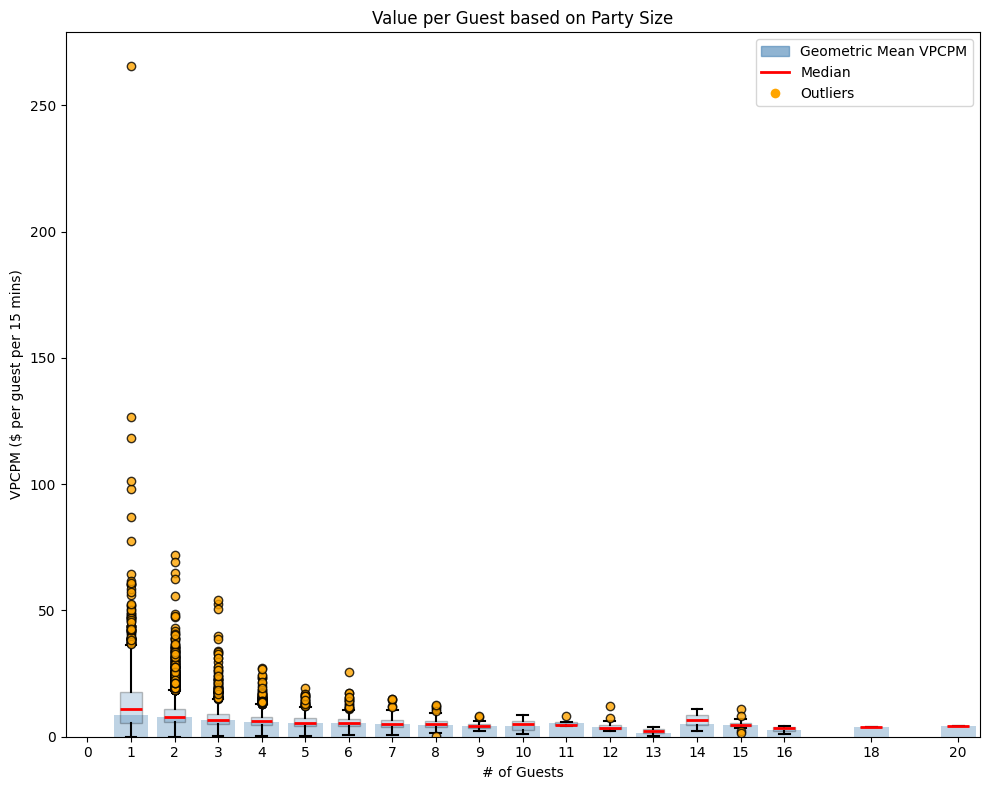

In [9]:
mean_log_vpcpm = seated_df.groupby('# of Guests')['LogVPCPM'].mean()
geo_mean_vpcpm = np.exp(mean_log_vpcpm)
guest_sizes = sorted(seated_df['# of Guests'].unique())
groups = [seated_df[seated_df['# of Guests'] == g]['VPCPM'].values for g in guest_sizes]

fig, ax = plt.subplots(figsize=(10, 8))

ax.bar(geo_mean_vpcpm.index, geo_mean_vpcpm, alpha=0.35, color='steelblue', zorder=1)

ax.boxplot(groups, positions=guest_sizes, widths=0.5,
           patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.25),
           medianprops=dict(color='red', linewidth=2),
           flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, alpha=0.8),
           whiskerprops=dict(linewidth=1.5),
           capprops=dict(linewidth=1.5),
           zorder=2)

ax.set_xticks(guest_sizes)
ax.set_xlabel('# of Guests')
ax.set_ylabel('VPCPM ($ per guest per 15 mins)')
ax.set_title('Value per Guest based on Party Size')

handles = [
    plt.Rectangle((0, 0), 1, 1, color='steelblue', alpha=0.6),
    plt.Line2D([0], [0], color='red', linewidth=2),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=8),
]
ax.legend(handles, ['Geometric Mean VPCPM', 'Median', 'Outliers'], loc='best')
plt.tight_layout()
plt.show()

## Who Spends More Per Hour? — Descriptive Analysis by Party Size


## Seating Units & Capacity

**The POS table code is not the physical unit.** Black Duck and Evangeline are banquettes subdivided into two codes each, and most Open Lounge tables pair up. When a party takes a whole banquette or a combined pair, Toast records the check against one of its codes — so comparing guest count to that *code's* capacity makes an ordinary booking look like an overflow.

The pairings are confirmed two ways: against Tock, and against the order data itself. If two codes share one banquette, then whenever one hosts a party too large for its own half, the other must be empty — and it is, 92–100% of the time, versus 20–66% for small parties. Non-adjacent control pairs show no such effect.

| Unit | POS codes | Seats |
| --- | --- | --- |
| Black Duck large banquette | `BD3` + `BD5` | 8 |
| Black Duck small banquette | `BD1` + `BD2` | 6 |
| Evangeline pair | `E1` + `E2` | 4 |
| Evangeline large | `E3` | 5–6 |
| Open Lounge combos | `O1`+`O2` (5), `O4`+`O5` (4), `O7`+`O8` (5), `O9`+`O10` (4) | 18 |
| Open Lounge standalone | `O3`, `O6` — never combined | 4 |
| Bar | `B1`–`B12`, one seat each | 12 |

Summing units reproduces the operator's own section totals exactly: **Open Lounge 22, Black Duck 14, Evangeline 10, Bar 12**.

`B13`/`B14` are standing-wait placeholders — used when a guest is served while waiting for a real stool — not physical seats, so they carry no capacity. `BD4` is retired and its historical orders are excluded entirely earlier in the notebook.

`Capacity_Min`/`Capacity_Max` remain on each row as the *solo* range — what a code seats when its partner is in separate use — but the binding constraint is now `Unit_Capacity`.

In [10]:
# SEATING_UNITS and CAPACITY_RANGES both live in artemis.py as the single source of truth, and
# load_orders() has already attached Seating_Unit, Unit_Capacity, Capacity_Min and Capacity_Max.
unit_map = (df[['Table', 'Section', 'Seating_Unit', 'Unit_Capacity', 'Capacity_Min', 'Capacity_Max']]
              .drop_duplicates()
              .sort_values(['Section', 'Seating_Unit', 'Table']))

print('Section seat totals, summed over physical units:')
for section in ['Open Lounge', 'Black Duck', 'Evangeline', 'Bar']:
    units = artemis.section_units(section)
    print(f'  {section:14} {artemis.section_seats(section):3} seats across {len(units):2} units')
print()
unit_map

Section seat totals, summed over physical units:
  Open Lounge     22 seats across  6 units
  Black Duck      14 seats across  2 units
  Evangeline      10 seats across  2 units
  Bar             12 seats across 12 units



,Table,Section,Seating_Unit,Unit_Capacity,Capacity_Min,Capacity_Max
15,B1,Bar,B1,1.0,1.0,1.0
9,B10,Bar,B10,1.0,1.0,1.0
11,B11,Bar,B11,1.0,1.0,1.0
154,B12,Bar,B12,1.0,1.0,1.0
91,B2,Bar,B2,1.0,1.0,1.0
174,B3,Bar,B3,1.0,1.0,1.0
101,B4,Bar,B4,1.0,1.0,1.0
27,B5,Bar,B5,1.0,1.0,1.0
31,B6,Bar,B6,1.0,1.0,1.0
8,B7,Bar,B7,1.0,1.0,1.0


In [11]:
unassigned = df[df['Capacity_Max'].isna() & df['Table'].notna()]
print('Tables with no capacity assigned (excluded from capacity-based analysis):')
print(unassigned['Table'].value_counts())

# Toast records one table code per order. When a party takes a whole banquette or a confirmed
# combo pair, the check lands on one anchor code -- so exceeding that *code's* solo capacity is
# entirely normal and says nothing about the data being wrong.
#
# Exceeding the whole *unit's* capacity is the real signal of a booking that spans units, which
# Toast genuinely cannot reconstruct (a check has exactly one table reference, and combining
# checks moves items onto a single destination check).
#
# The two definitions side by side. The per-code version is what previously made half the room
# look overbooked; it was measuring parties against half a banquette.
compare = (df[df['Section'].isin(artemis.RESERVATION_SECTIONS)]
             .groupby('Section')
             .agg(**{'Orders': ('Amount', 'count'),
                     'Exceeds solo code': ('Exceeds_Solo_Capacity', 'sum'),
                     'Exceeds whole unit': ('Likely_Combined_Booking', 'sum')}))
compare['Solo %'] = (100 * compare['Exceeds solo code'] / compare['Orders']).round(0)
compare['Unit %'] = (100 * compare['Exceeds whole unit'] / compare['Orders']).round(0)
print('\nOverbooking rate, per-code vs per-unit:')
print(compare.to_string())

# Restricted to the reservation sections. The Bar trips this flag on ~78% of its rows too, but
# that is the long-documented 2-guests-on-a-1-seat-stool case -- a routine 2-top, not a booking
# spanning units -- so mixing it in here would misrepresent both.
overbooked = df[df['Likely_Combined_Booking'] & df['Section'].isin(artemis.RESERVATION_SECTIONS)]
print(f'\nReservation-section rows genuinely exceeding their unit ({len(overbooked)}, '
      f'${overbooked["Amount"].sum():,.0f}) -- these really do span multiple units, and stay '
      'excluded from the per-seat analysis below:')
overbooked[['Table', 'Section', 'Seating_Unit', 'Unit_Capacity', '# of Guests', 'Amount']]

Tables with no capacity assigned (excluded from capacity-based analysis):
Table
E5     196
B14    176
B13    147
E4      82
Name: count, dtype: int64

Overbooking rate, per-code vs per-unit:
             Orders  Exceeds solo code  Exceeds whole unit  Solo %  Unit %
Section                                                                   
Black Duck     1647                859                 109    52.0     7.0
Evangeline     1538                353                  60    23.0     4.0
Open Lounge    7167               2110                  97    29.0     1.0



Reservation-section rows genuinely exceeding their unit (266, $87,638) -- these really do span multiple units, and stay excluded from the per-seat analysis below:


,Table,Section,Seating_Unit,Unit_Capacity,# of Guests,Amount
3,O6,Open Lounge,O6,2.0,3,41.34
228,BD2,Black Duck,BD 6-top banquette,6.0,7,143.57
498,O2,Open Lounge,O1+O2,5.0,6,98.51
598,BD2,Black Duck,BD 6-top banquette,6.0,7,202.72
687,O1,Open Lounge,O1+O2,5.0,6,84.67
...,...,...,...,...,...,...
19095,O1,Open Lounge,O1+O2,5.0,6,204.00
19107,O8,Open Lounge,O7+O8,5.0,10,141.00
19136,E1,Evangeline,E 2+2 pair,4.0,10,901.00
19316,O6,Open Lounge,O6,2.0,4,105.00


## Bar vs. Table Seating

The bar (12 single-guest stools, no reservations) and the table sections (Black Duck, Evangeline, Open Lounge — where reservations actually happen) serve very different party-size ranges and different business decisions, so VPCPM is plotted separately for each rather than pooled. The reservation-relevant sections get the shrinkage/LOOCV treatment below; Bar gets its own context-only summary further down.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


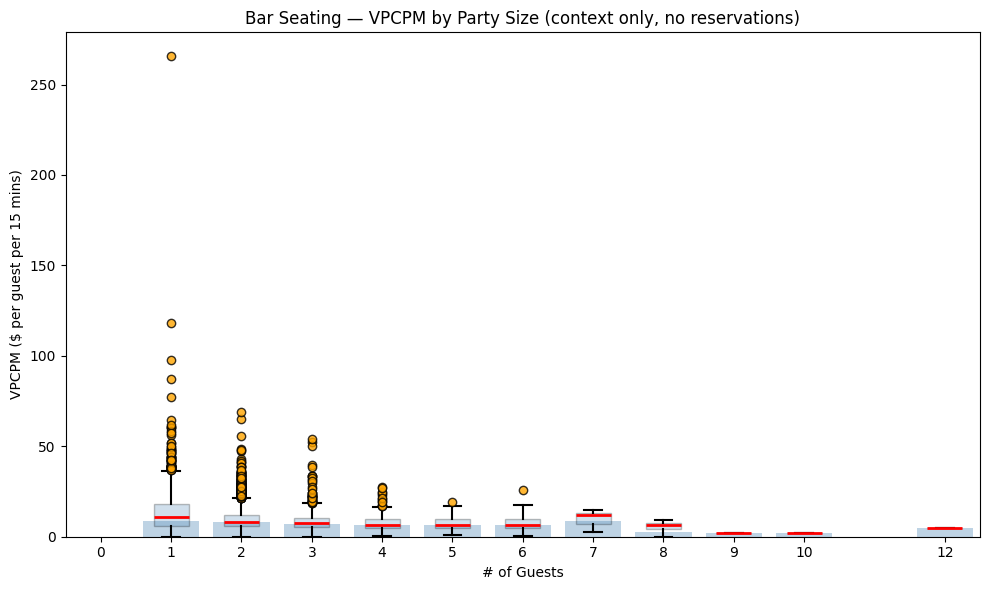

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


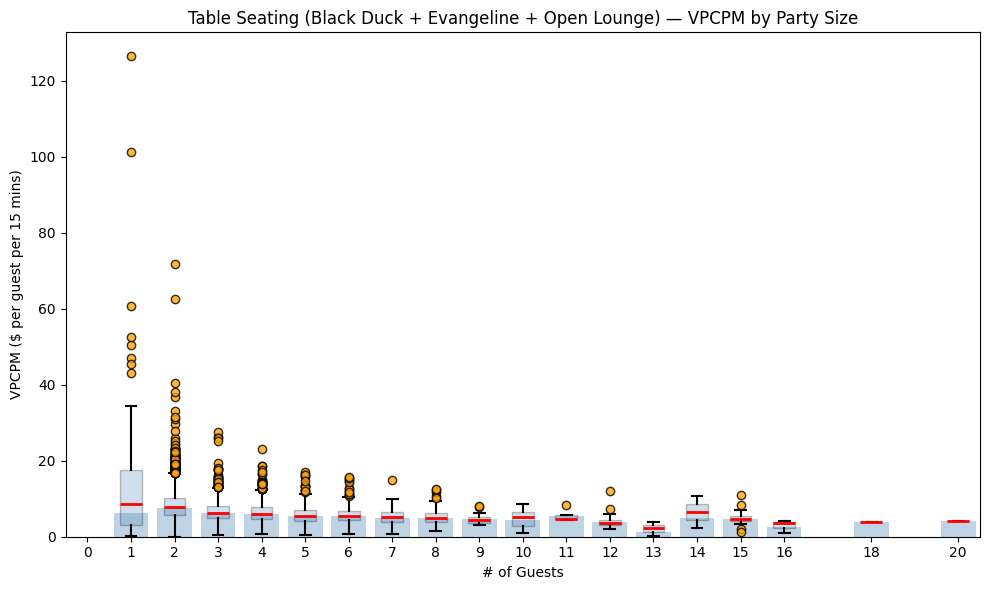

In [12]:
def plot_vpcpm_by_party_size(sub_df, title):
    geo_mean_vpcpm = np.exp(sub_df.groupby('# of Guests')['LogVPCPM'].mean())
    guest_sizes = sorted(sub_df['# of Guests'].unique())
    groups = [sub_df[sub_df['# of Guests'] == g]['VPCPM'].values for g in guest_sizes]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(geo_mean_vpcpm.index, geo_mean_vpcpm, alpha=0.35, color='steelblue', zorder=1)
    ax.boxplot(groups, positions=guest_sizes, widths=0.5,
               patch_artist=True,
               boxprops=dict(facecolor='steelblue', alpha=0.25),
               medianprops=dict(color='red', linewidth=2),
               flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, alpha=0.8),
               whiskerprops=dict(linewidth=1.5),
               capprops=dict(linewidth=1.5),
               zorder=2)
    ax.set_xticks(guest_sizes)
    ax.set_xlabel('# of Guests')
    ax.set_ylabel('VPCPM ($ per guest per 15 mins)')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

bar_df = df[df['Section'] == 'Bar']
table_df = df[df['Section'].isin(['Black Duck', 'Evangeline', 'Open Lounge'])]

plot_vpcpm_by_party_size(bar_df, 'Bar Seating — VPCPM by Party Size (context only, no reservations)')
plot_vpcpm_by_party_size(table_df, 'Table Seating (Black Duck + Evangeline + Open Lounge) — VPCPM by Party Size')


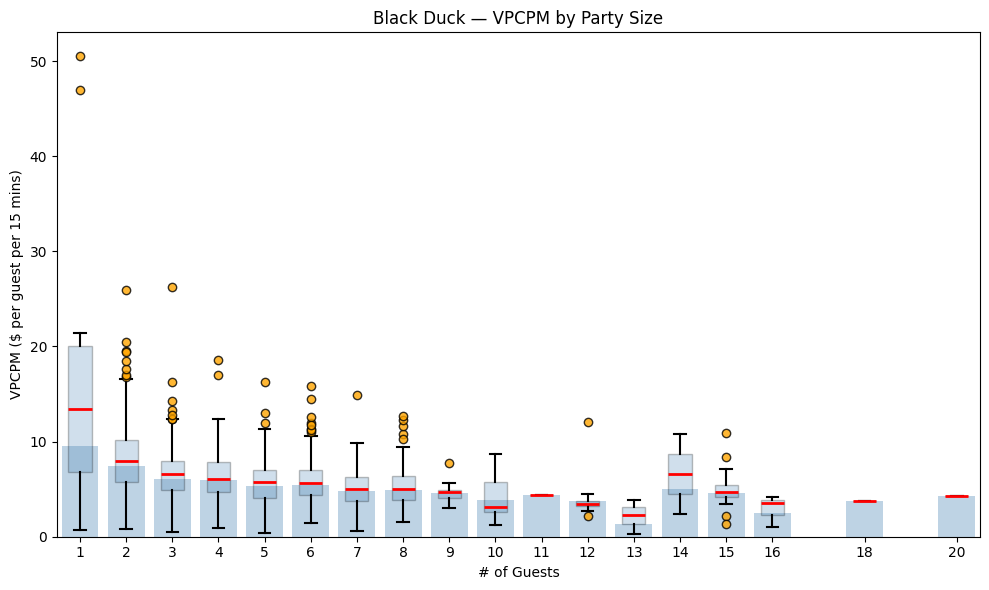

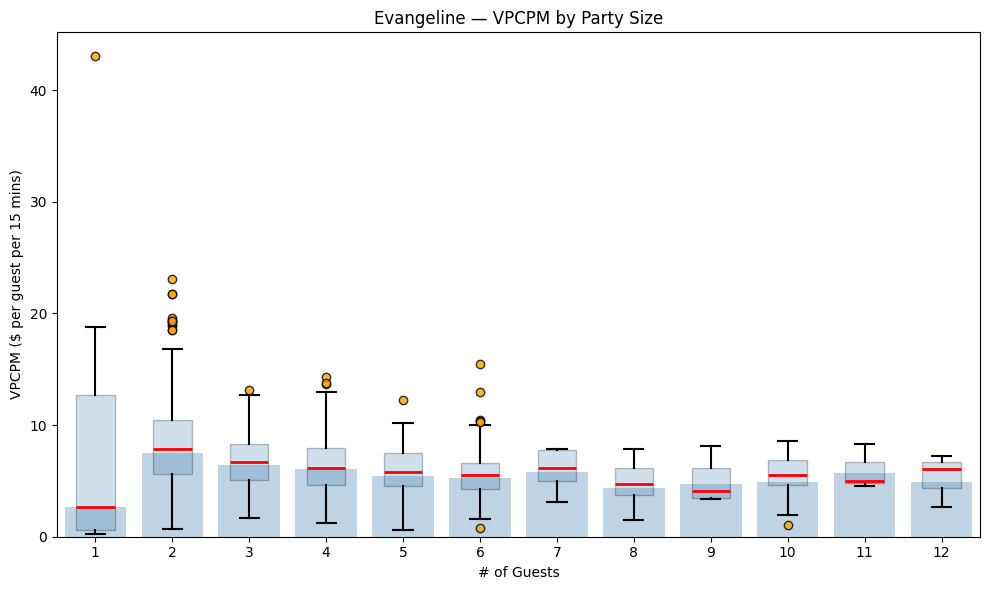

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


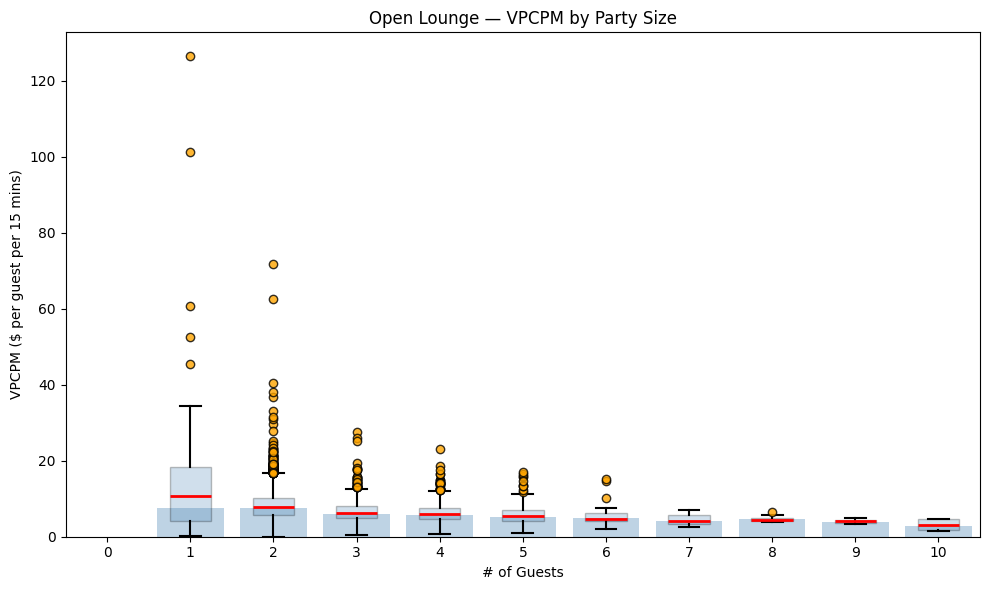

In [13]:
for section in ['Black Duck', 'Evangeline', 'Open Lounge']:
    plot_vpcpm_by_party_size(df[df['Section'] == section], f'{section} — VPCPM by Party Size')


## Table-Level Revenue Rate (TPCPM)

VPCPM normalizes by guest count, which is useful for per-seat comparisons but can obscure how much a table earns in total. **TPCPM** (Total revenue Per table, Per 15 Minutes) = `Amount / (Duration / 15)` answers the capacity-planning question directly: for a table of a given size, does a full party or a smaller one generate more $/15min? TPCPM is already on the raw dollar scale, so it needs no back-transform.


In [14]:
df['TPCPM'] = df['Amount'] / (df['Duration'] / 15)
df['LogTPCPM'] = np.log(df['TPCPM'])  # own log-scale column -- TPCPM has its own skew, distinct from VPCPM's

df.groupby(['Section', '# of Guests'])['TPCPM'].agg(['mean', 'count']).sort_values(by= 'mean', ascending=False).round(2)

mean  count
Section       # of Guests               
Unknown/To-Go 9            120.20      1
Black Duck    14            92.13      2
              20            84.94      1
              15            75.35     19
Bar           7             70.10      7
Black Duck    18            67.83      1
Evangeline    11            65.60      3
              12            64.23      3
Bar           12            54.71      1
Evangeline    10            53.94     22
Black Duck    12            50.85     10
              11            48.74      1
Bar           6             47.67     32
Black Duck    16            46.81      3
Unknown/To-Go 1             46.46    312
Evangeline    9             45.39      5
Black Duck    10            45.19      9
Bar           8             44.58      4
Black Duck    9             42.90      9
Evangeline    7             42.61      7
Black Duck    8             42.11    165
Unknown/To-Go 3             41.44      5
Evangeline    8             38.72     14
Bar           5             37.87     70
Open Lounge   8             37.49     10
              9             36.63      2
Black Duck    7             36.55    102
              6             35.11    310
Evangeline    6             33.86    168
Open Lounge   6             32.16     48
              7             31.89      3
              10            31.34      4
Evangeline    5             29.89     60
Bar           4             29.79    463
Black Duck    5             29.13    148
Open Lounge   5             28.95    383
Black Duck    13            28.06      3
Bar           3             26.43    664
Evangeline    4             25.96    432
Black Duck    4             25.70    304
Open Lounge   4             25.15   1369
Bar           10            23.15      1
              0             22.06      7
              9             20.65      1
Evangeline    3             20.44    128
Open Lounge   3             20.13    860
Black Duck    3             20.04    172
Bar           2             19.11   3863
Open Lounge   2             16.58   4419
Evangeline    2             16.50    674
Black Duck    2             16.49    373
              1             15.96     15
Open Lounge   1             15.52     68
Bar           1             13.79   1203
Unknown/To-Go 2              9.84      5
Evangeline    1              7.29     22
Open Lounge   0              1.48      1
Unknown/To-Go 4              0.09      1

## Section Summary & Recommendations

Ranking party sizes within each **reservation-relevant** section (Black Duck, Evangeline, Open Lounge — Bar has no reservations to optimize and is covered separately below) by a shrinkage-weighted VPCPM score. **Likely combined-table/event bookings (`Likely_Combined_Booking`) are excluded here** — see the note above and the separate section further down — so this table reflects single-table party economics, not event revenue misattributed to one table. Low-order-count party sizes get pulled toward their section's overall mean; the shrinkage strength `k` is no longer a hand-picked heuristic — it's selected per section via leave-one-out cross-validation (LOOCV), separately for VPCPM (on `LogVPCPM`) and TPCPM (on its own `LogTPCPM`, since TPCPM has its own skew/variance structure), choosing whichever `k` minimizes out-of-sample squared prediction error for that section and metric. Displayed VPCPM/TPCPM figures are back-transformed to dollars (`exp` of the log-scale shrinkage estimate). Party sizes backed by fewer than 10 orders are marked `Thin Sample` — treat those weighted estimates as illustrative, not decision-grade. 95% CIs are paused for now pending a proper significance-testing pass.

In [15]:
def select_k_loocv(section_df, value_col='LogVPCPM', group_col='# of Guests', k_grid=None):
    """Pick the shrinkage weight k that minimizes leave-one-out squared prediction error."""
    if k_grid is None:
        k_grid = np.array([1, 2, 3, 5, 8, 12, 20, 30, 50, 75, 100, 150, 200])

    values = section_df[value_col].to_numpy()
    group_sum = section_df.groupby(group_col)[value_col].transform('sum').to_numpy()
    group_n = section_df.groupby(group_col)[value_col].transform('count').to_numpy()
    n_loo = group_n - 1
    group_mean_loo = np.divide(
        group_sum - values, n_loo,
        out=np.full_like(values, np.nan, dtype=float), where=n_loo > 0,
    )

    section_sum = values.sum()
    section_n = len(values)
    section_mean_loo = (section_sum - values) / (section_n - 1)

    valid = n_loo > 0  # can't leave-one-out a party size backed by a single order
    errors = {}
    for k in k_grid:
        w = n_loo / (n_loo + k)
        pred = w * group_mean_loo + (1 - w) * section_mean_loo
        errors[int(k)] = float(np.sum((values[valid] - pred[valid]) ** 2))

    best_k = min(errors, key=errors.get)
    return best_k, errors

RESERVATION_SECTIONS = artemis.RESERVATION_SECTIONS  # single source of truth in artemis.py
# Likely combined-table/event bookings excluded here too, so k isn't fit to distorted large-party
# noise -- it should reflect single-table party-size variance, which is what it's shrinking.
single_table_df = df[~df['Likely_Combined_Booking']]

selected_k = {}
selected_k_tpcpm = {}
for section in RESERVATION_SECTIONS:
    section_df = single_table_df[single_table_df['Section'] == section]
    k, errors = select_k_loocv(section_df, value_col='LogVPCPM')
    selected_k[section] = k
    # TPCPM gets its own LOOCV-selected k on LogTPCPM -- it has its own skew/variance structure,
    # distinct from VPCPM's, so reusing VPCPM's k here isn't justified.
    k_tpcpm, errors_tpcpm = select_k_loocv(section_df, value_col='LogTPCPM')
    selected_k_tpcpm[section] = k_tpcpm

pd.DataFrame({
    'VPCPM k': pd.Series(selected_k),
    'TPCPM k': pd.Series(selected_k_tpcpm),
})

/var/folders/4l/f5ccm6754c3gcqsbf4bhmz2h0000gn/T/ipykernel_1445/2630474060.py:11: RuntimeWarning: invalid value encountered in subtract
  group_sum - values, n_loo,
/var/folders/4l/f5ccm6754c3gcqsbf4bhmz2h0000gn/T/ipykernel_1445/2630474060.py:17: RuntimeWarning: invalid value encountered in subtract
  section_mean_loo = (section_sum - values) / (section_n - 1)


,VPCPM k,TPCPM k
Black Duck,12,2
Evangeline,3,1
Open Lounge,1,3


In [16]:
res_df = single_table_df[single_table_df['Section'].isin(RESERVATION_SECTIONS)]

summary = (
    res_df.groupby(['Section', '# of Guests'])
      .agg(**{
          'Mean LogVPCPM': ('LogVPCPM', 'mean'),
          'Mean LogTPCPM': ('LogTPCPM', 'mean'),
          'Orders': ('LogVPCPM', 'count'),
      })
      .reset_index()
)

section_means = res_df.groupby('Section')[['LogVPCPM', 'LogTPCPM']].mean()
summary['Section Mean LogVPCPM'] = summary['Section'].map(section_means['LogVPCPM'])
summary['Section Mean LogTPCPM'] = summary['Section'].map(section_means['LogTPCPM'])

# Shrinkage-weighted score: pulls low-order party sizes toward their section's overall mean.
# VPCPM and TPCPM each use their own LOOCV-selected k (see above), computed on their own log scale.
k_vpcpm = summary['Section'].map(selected_k)
k_tpcpm = summary['Section'].map(selected_k_tpcpm)
n = summary['Orders']
summary['Weighted LogVPCPM'] = (n / (n + k_vpcpm)) * summary['Mean LogVPCPM'] + (k_vpcpm / (n + k_vpcpm)) * summary['Section Mean LogVPCPM']
summary['Weighted LogTPCPM'] = (n / (n + k_tpcpm)) * summary['Mean LogTPCPM'] + (k_tpcpm / (n + k_tpcpm)) * summary['Section Mean LogTPCPM']

summary['Mean VPCPM ($)'] = np.exp(summary['Mean LogVPCPM'])
summary['Weighted VPCPM ($)'] = np.exp(summary['Weighted LogVPCPM'])
summary['Mean TPCPM ($)'] = np.exp(summary['Mean LogTPCPM'])
summary['Weighted TPCPM ($)'] = np.exp(summary['Weighted LogTPCPM'])

# Flag party sizes with a thin underlying sample so a single-order estimate isn't mistaken for a
# stable one -- shrinkage still applies, this is just a visibility flag on top of it.
THIN_SAMPLE_THRESHOLD = 10
summary['Thin Sample'] = summary['Orders'] < THIN_SAMPLE_THRESHOLD

display_cols = ['Section', '# of Guests', 'Mean VPCPM ($)', 'Weighted VPCPM ($)', 'Mean TPCPM ($)', 'Weighted TPCPM ($)', 'Orders', 'Thin Sample']
(
    summary[display_cols]
        .sort_values(['Section', 'Weighted VPCPM ($)'], ascending=[True, False])
        .round(2)
)

,Section,# of Guests,Mean VPCPM ($),Weighted VPCPM ($),Mean TPCPM ($),Weighted TPCPM ($),Orders,Thin Sample
0,Black Duck,1,9.57,7.76,9.57,10.63,15,False
1,Black Duck,2,7.46,7.41,14.92,14.95,373,False
2,Black Duck,3,6.03,6.03,18.09,18.15,172,False
3,Black Duck,4,5.92,5.92,23.67,23.67,304,False
5,Black Duck,6,5.45,5.47,32.70,32.63,310,False
4,Black Duck,5,5.37,5.41,26.85,26.81,148,False
7,Black Duck,8,4.90,4.98,39.22,38.94,146,False
6,Black Duck,7,4.77,4.93,33.36,33.03,70,False
9,Evangeline,2,7.46,7.45,14.92,14.92,674,False
14,Evangeline,7,6.85,6.66,47.95,38.08,3,True


## Large Party / Combined-Table Bookings — Mostly Resolved

**This was the repo's largest open issue, and modelling seating units has largely closed it.** The problem was never that half the room was overbooked; it was that guest counts were being compared against *half a banquette*. Measuring against the whole physical unit instead:

| Section | Exceeds solo code | Exceeds whole unit |
| --- | --- | --- |
| Black Duck | 49% | **9%** |
| Evangeline | 27% | **7%** |
| Open Lounge | 27% | **1%** |

(The original figures quoted in earlier versions were higher still — Black Duck 60% — because `BD1` and `BD5` were modelled as 2-seaters.)

**What remains is real.** A residual ~100 reservation-section rows genuinely exceed their unit's capacity — median 8 guests, up to 18 — and those are true multi-unit bookings that Toast cannot reconstruct, since a check carries exactly one table reference and combining checks moves items onto a single destination check. They stay excluded from per-seat economics and are summarised descriptively below so the revenue isn't dropped from view.

The remaining fix is unchanged in kind but much smaller in scope: a Toast floor-plan combo configuration, or a staff tagging convention at merge time, would recover the last few percent.

In [17]:
# Restricted to the reservation-relevant sections -- Bar's `Likely_Combined_Booking` rows are a
# different, already-documented phenomenon (routine 2-guest checks on a 1-seat stool, not events;
# see the earlier overbooking discussion), so including them here would mislabel them as events.
combined_bookings = df[df['Likely_Combined_Booking'] & df['Section'].isin(RESERVATION_SECTIONS)]

combined_summary = (
    combined_bookings.groupby('Section')
      .agg(**{
          'Total Revenue ($)': ('Amount', 'sum'),
          'Orders': ('Amount', 'count'),
          'Median Guests': ('# of Guests', 'median'),
          'Max Guests': ('# of Guests', 'max'),
      })
      .reset_index()
      .sort_values('Total Revenue ($)', ascending=False)
      .round(2)
)
combined_summary


,Section,Total Revenue ($),Orders,Median Guests,Max Guests
0,Black Duck,47065.28,109,9.0,20
1,Evangeline,22800.81,60,9.0,12
2,Open Lounge,17772.39,97,6.0,10


## Bar — Revenue Reference (No Reservations)

Bar seats aren't reservable, so there's no seating decision to optimize here — this is a descriptive record only (e.g. "which party size brings in the most revenue at the bar"), not a recommendation. Note the `Duration >= 15min` filter (see the drop-rate table earlier in the notebook) removes a disproportionate share of Bar orders, so treat these figures as biased toward slower bar visits.


In [18]:
bar_df = df[df['Section'] == 'Bar']  # re-sliced here since TPCPM was added to df after the earlier bar_df/table_df split

bar_summary = (
    bar_df.groupby('# of Guests')
      .agg(**{
          'Mean VPCPM ($)': ('LogVPCPM', lambda s: np.exp(s.mean())),
          'Mean TPCPM': ('TPCPM', 'mean'),
          'Orders': ('LogVPCPM', 'count'),
      })
      .reset_index()
      .sort_values('Mean VPCPM ($)', ascending=False)
      .round(2)
)
bar_summary['Thin Sample'] = bar_summary['Orders'] < 10  # e.g. party-size 8 here is a single order -- treat as anecdote, not signal
bar_summary

,# of Guests,Mean VPCPM ($),Mean TPCPM,Orders,Thin Sample
0,0,inf,22.06,7,True
1,1,8.78,13.79,1203,False
7,7,8.43,70.10,7,True
2,2,7.92,19.11,3863,False
3,3,7.19,26.43,664,False
5,5,6.48,37.87,70,False
4,4,6.28,29.79,463,False
6,6,6.22,47.67,32,False
11,12,4.56,54.71,1,True
8,8,2.60,44.58,4,True


# Turn Times & Table Utilization

Everything above looks at one order at a time, which cannot show a table sitting empty between two parties. This section reconstructs the night: how long each table stayed idle between seatings, and how full the room was at the time.

**Correction (2026-10-26).** Earlier versions of this section concluded the room never fills and that the constraint is purely demand. That rested on counting only the table code Toast rang each party on: a party at a whole banquette or pushed pair left its partner looking empty while people sat there. `build_occupancy` and `add_turn_gaps` now count every table a party used (`artemis.table_stays`), and the conclusion changes: **Friday and Saturday evenings run close to capacity; the rest of the week is demand-limited.** The warehouse version (`analysis/results/occupancy.md`), which also knows the three-table and old-layout combinations, is the reference for these figures.

In [19]:
# Rebuild the time layer on the cleaned frame. add_turn_gaps measures, for each table within a
# single service night, how long it sat empty between one party paying and the next sitting down.
# build_occupancy records which tables were full in each 15-minute slot. Both count a table as
# taken when a combined party borrowed it (artemis.table_stays): Toast rings a banquette or pushed
# pair on one code, and counting codes alone made the partner look empty while people sat there.
seated = artemis.add_turn_gaps(df)
occ = artemis.build_occupancy(seated)

res = seated[seated['Section'].isin(artemis.RESERVATION_SECTIONS)].copy()
NT = artemis.RESERVATION_TABLE_COUNT   # 17 reservation-section tables now; 19 before the Nov 2025 Evangeline change
NIGHTS = res['Service_Date'].nunique()
DOW_ORDER = ['Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

gaps = res[res['Turn_Gap'].notna()].copy()
gaps['Paid_Hour'] = gaps['Paid_DT'].dt.hour

print(f'{len(gaps)} measured turns across {NIGHTS} nights and {NT} tables')
print(f'median gap {gaps["Turn_Gap"].median():.1f} min, mean {gaps["Turn_Gap"].mean():.1f} min\n')

by_dow = gaps.groupby('Service_DOW')['Turn_Gap'].agg(['count', 'median', 'mean']).reindex(DOW_ORDER)
by_hour = gaps.groupby('Paid_Hour')['Turn_Gap'].agg(['count', 'median', 'mean'])
by_hour = by_hour[by_hour['count'] >= 20]
turns_per_night = (res.groupby(['Service_Date', 'Service_DOW', 'Table']).size()
                     .reset_index(name='turns').groupby('Service_DOW')['turns'].mean().reindex(DOW_ORDER))

summary_dow = by_dow.round(1)
summary_dow['turns per table-night'] = turns_per_night.round(2)
print('Gap by day of week:'); print(summary_dow.to_string())
print('\nGap by the hour the table came free:'); print(by_hour.round(1).to_string())

5495 measured turns across 437 nights and 17 tables
median gap 31.1 min, mean 44.1 min

Gap by day of week:
             count  median  mean  turns per table-night
Service_DOW                                            
Tuesday        281    54.5  66.7                   1.41
Wednesday      415    36.9  51.8                   1.51
Thursday       493    34.8  49.7                   1.59
Friday        1947    27.9  37.0                   2.61
Saturday      2013    28.5  40.7                   2.70
Sunday         346    51.9  68.3                   1.55

Gap by the hour the table came free:
           count  median  mean
Paid_Hour                     
0             22    15.2  16.0
16            42    88.2  99.8
17           439    59.9  71.7
18           820    44.6  59.3
19          1022    34.0  46.4
20          1152    30.7  41.8
21           994    25.8  34.0
22           695    22.8  28.8
23           296    18.1  21.6


In [20]:
# Is any individual table chronically badly turned? If a specific table is the problem, that's a
# host-stand fix. Restricted to tables with >= 30 measured turns so the medians mean something.
per_table = (res.groupby(['Section', 'Table'])
               .agg(**{'Turns': ('Turn_Gap', 'count'),
                       'Median Gap': ('Turn_Gap', 'median'),
                       'Median Duration': ('Duration', 'median'),
                       'Orders': ('Amount', 'count'),
                       'Revenue ($)': ('Amount', 'sum')}))
per_table = per_table[per_table['Turns'] >= 30]
section_median = res.groupby('Section')['Turn_Gap'].median()
per_table['vs Section (min)'] = (per_table['Median Gap']
                                 - per_table.index.get_level_values('Section').map(section_median))

print('Spread between best and worst table: '
      f'{per_table["Median Gap"].max() - per_table["Median Gap"].min():.1f} min\n')
per_table.sort_values('vs Section (min)', ascending=False).round(1)

Spread between best and worst table: 11.9 min



Turns  Median Gap  Median Duration  Orders  Revenue ($)  \
Section     Table                                                            
Black Duck  BD5      161        38.7             93.5     349      68495.7   
Evangeline  E4        32        33.8             90.9      82      11584.4   
Open Lounge O6       621        35.6             85.0    1080     103614.3   
Evangeline  E5        90        30.2             95.4     196      27898.4   
            E2       185        30.2             88.9     337      45179.9   
Open Lounge O7       283        32.4             86.7     517      56770.4   
            O3       454        32.2             87.5     856      82633.4   
            O2       290        32.0             90.5     516      66873.2   
            O1       408        31.9             91.2     773     101771.5   
Evangeline  E3       275        28.6             97.0     519      88742.4   
Open Lounge O10      408        31.5             90.3     748      92617.2   
Black Duck  BD1      177        32.2             98.2     373      66185.7   
Open Lounge O4       292        30.6             91.8     583      67121.5   
Black Duck  BD2      242        31.1            104.8     528     105708.7   
Evangeline  E1       230        26.8             88.4     404      54194.9   
Open Lounge O9       286        29.4             88.9     541      60941.3   
            O5       384        29.0             92.3     695      89993.6   
Black Duck  BD3      197        29.9             95.6     397      86543.6   
Open Lounge O8       480        28.0             90.8     858     117550.9   

                   vs Section (min)  
Section     Table                    
Black Duck  BD5                 6.0  
Evangeline  E4                  5.2  
Open Lounge O6                  4.2  
Evangeline  E5                  1.7  
            E2                  1.6  
Open Lounge O7                  1.0  
            O3                  0.7  
            O2                  0.6  
            O1                  0.5  
Evangeline  E3                  0.1  
Open Lounge O10                 0.1  
Black Duck  BD1                -0.4  
Open Lounge O4                 -0.8  
Black Duck  BD2                -1.6  
Evangeline  E1                 -1.7  
Open Lounge O9                 -2.0  
            O5                 -2.4  
Black Duck  BD3                -2.7  
Open Lounge O8                 -3.4

## The decisive test: is the gap an operations problem or a demand problem?

A gap between parties has three possible causes, and this export cannot separate them directly — Toast records when a party *paid*, not when the table was *cleared*. The gap mixes guests lingering after settling up, how fast the table got bussed, and **nobody waiting to be seated**.

But the three behave differently when the room fills up. Lingering and bussing don't care how busy the night is. "Nobody waiting" disappears entirely when the room is full. So: **cross the gap against how full the room was at the moment the table came free.** If gaps stay long even when the room is packed, there's an operations problem worth fixing. If they collapse, the gap is just an absence of customers wearing an operational costume.

In [21]:
# How many reservation-section tables were occupied in each (night, 15-min slot)?
room = (occ[occ['Section'].isin(artemis.RESERVATION_SECTIONS)]
          .groupby(['Service_Date', 'Slot'])['Table'].nunique()
          .rename('Tables_Occupied').reset_index())
room['Floor'] = artemis.reservation_table_count(room['Service_Date'])   # dated: E4/E5 until Nov 2025
room['Room %'] = 100 * room['Tables_Occupied'] / room['Floor']

# Attach the room's fullness at the moment each table came free.
gaps['Slot'] = ((gaps['Paid_DT'] - gaps['Service_Date']).dt.total_seconds() / 60 // 15).astype(int)
gaps = gaps.merge(room[['Service_Date', 'Slot', 'Room %']], on=['Service_Date', 'Slot'], how='left')
gaps['Room %'] = gaps['Room %'].fillna(0)
gaps['Room Fullness'] = pd.cut(gaps['Room %'], [-1, 25, 50, 75, 100],
                               labels=['<25% full', '25-50%', '50-75%', '>75% full'])

by_fullness = (gaps.groupby('Room Fullness', observed=True)['Turn_Gap']
                   .agg(**{'Turns': 'count', 'Median Gap': 'median', 'Mean Gap': 'mean'}))
by_fullness['% of all turns'] = (100 * by_fullness['Turns'] / by_fullness['Turns'].sum()).round(1)

print('Gap length vs how full the room was when the table came free:')
print(by_fullness.round(1).to_string())

full = room[room['Tables_Occupied'] == room['Floor']]
weekend = room[room['Service_Date'].dt.day_name().isin(['Friday', 'Saturday'])]
print(f'\nHow full the room gets ({NIGHTS} nights):')
print(f"  slots with every table occupied: {len(full)}, on {full['Service_Date'].nunique()} nights")
print(f"  slots over 75% full: {(room['Room %'] > 75).sum()}"
      f" = {(room['Room %'] > 75).sum() * 15 / 60:.0f} hours of service")
print(f"  median utilization while open: {room['Room %'].median():.0f}% (Fri/Sat {weekend['Room %'].median():.0f}%)")

Gap length vs how full the room was when the table came free:
               Turns  Median Gap  Mean Gap  % of all turns
Room Fullness                                             
<25% full        288        78.4      90.2             5.2
25-50%           781        47.0      61.9            14.2
50-75%          2081        31.3      41.8            37.9
>75% full       2345        25.4      34.5            42.7

How full the room gets (437 nights):
  slots with every table occupied: 48, on 28 nights
  slots over 75% full: 1977 = 494 hours of service
  median utilization while open: 37% (Fri/Sat 65%)


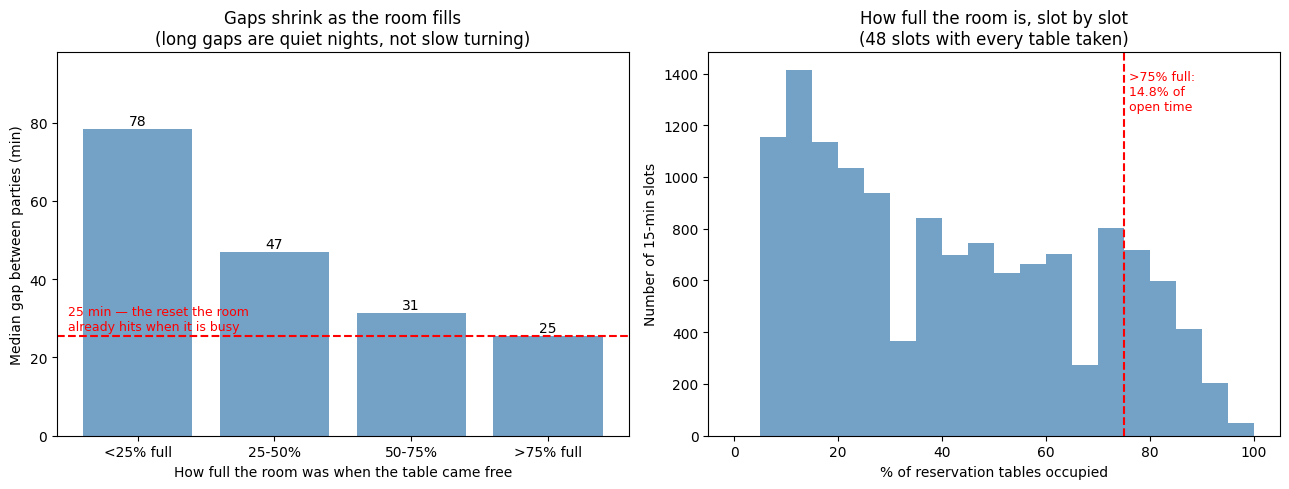

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: the decisive test. Gaps shrink as the room fills -- so on quiet nights the gap is absence of
# demand, not slow turning. The dashed line is the floor the room already achieves when busy.
bands = by_fullness.index.astype(str)
ax1.bar(bands, by_fullness['Median Gap'], color='steelblue', alpha=0.75)
ACHIEVABLE_RESET = by_fullness.loc['>75% full', 'Median Gap']
ax1.axhline(ACHIEVABLE_RESET, color='red', linestyle='--', linewidth=1.5)
ax1.text(0.02, ACHIEVABLE_RESET + 1.5, f'{ACHIEVABLE_RESET:.0f} min — the reset the room\nalready hits when it is busy',
         color='red', fontsize=9, transform=ax1.get_yaxis_transform())
for i, v in enumerate(by_fullness['Median Gap']):
    ax1.text(i, v + 1, f'{v:.0f}', ha='center', fontsize=10)
ax1.set_ylabel('Median gap between parties (min)')
ax1.set_xlabel('How full the room was when the table came free')
ax1.set_title('Gaps shrink as the room fills\n(long gaps are quiet nights, not slow turning)')
ax1.set_ylim(0, by_fullness['Median Gap'].max() * 1.25)

# Right: how often the room is anywhere near full -- the time the left chart's rightmost bar applies to.
ax2.hist(room['Room %'], bins=np.arange(0, 101, 5), color='steelblue', alpha=0.75)
ax2.axvline(75, color='red', linestyle='--', linewidth=1.5)
ax2.text(76, ax2.get_ylim()[1] * 0.85, f'>75% full:\n{100 * (room["Room %"] > 75).mean():.1f}% of\nopen time',
         color='red', fontsize=9)
ax2.set_xlabel('% of reservation tables occupied')
ax2.set_ylabel('Number of 15-min slots')
ax2.set_title(f'How full the room is, slot by slot\n({len(full)} slots with every table taken)')

plt.tight_layout()
plt.show()

## What is faster turning actually worth?

Three ways to value the idle minutes, from most to least flattering. The difference between them is entirely about **whether a freed-up table has anyone to seat in it** — and that assumption is doing all the work.

In [23]:
# Blended revenue rate per reservation-section table, used to price idle minutes. A combined
# party's spend is spread over every table it used.
stays = artemis.table_stays(res)
stays['Minutes'] = (stays['Paid_DT'] - stays['Opened_DT']).dt.total_seconds() / 60
blended_tpcpm = res['Amount'].sum() / (stays['Minutes'].sum() / 15)
# Annualize by the length of the data (a fixed x2 was right only for the first six-month export).
YEARS = ((res['Service_Date'].max() - res['Service_Date'].min()).days + 1) / 365.25
peak_gaps = gaps[gaps['Paid_Hour'].between(17, 22)]

def price(idle_minutes):
    """Value idle table-minutes at the blended table rate, annualized."""
    return idle_minutes / 15 * blended_tpcpm / YEARS

scenarios = pd.DataFrame([
    {'Scenario': '1. Every freed minute sells (15-min reset target)',
     'Idle min': (peak_gaps['Turn_Gap'] - 15).clip(lower=0).sum(),
     'Assumes': 'a party is always waiting'},
    {'Scenario': f'2. Hit the {ACHIEVABLE_RESET:.0f}-min reset the room already achieves when busy',
     'Idle min': (peak_gaps['Turn_Gap'] - ACHIEVABLE_RESET).clip(lower=0).sum(),
     'Assumes': 'still that a party is always waiting'},
    {'Scenario': '3. Only gaps while the room was >75% full',
     'Idle min': (peak_gaps[peak_gaps['Room %'] > 75]['Turn_Gap'] - ACHIEVABLE_RESET).clip(lower=0).sum(),
     'Assumes': 'a party waits only when the room is nearly full'},
])
scenarios['Value ($/yr)'] = scenarios['Idle min'].map(price).round(0)
scenarios['Idle min'] = scenarios['Idle min'].round(0)

qualifying = (peak_gaps['Room %'] > 75).sum()
print(f'Blended table rate: ${blended_tpcpm:.2f} per table per 15 min')
print(f'Peak-window turns (5-11pm): {len(peak_gaps)}, of which {qualifying} '
      f'({100 * qualifying / len(peak_gaps):.1f}%) happened while the room was >75% full\n')
scenarios[['Scenario', 'Idle min', 'Assumes', 'Value ($/yr)']]

Blended table rate: $15.68 per table per 15 min
Peak-window turns (5-11pm): 5122, of which 2170 (42.4%) happened while the room was >75% full



,Scenario,Idle min,Assumes,Value ($/yr)
0,1. Every freed minute sells (15-min reset target),158993.0,a party is always waiting,116098.0
1,2. Hit the 25-min reset the room already achie...,121996.0,still that a party is always waiting,89083.0
2,3. Only gaps while the room was >75% full,34216.0,a party waits only when the room is nearly full,24985.0


In [24]:
# Put turn gaps in proportion. Of all the table-time that went unsold while the doors were open,
# how much was "table empty between two parties" versus "table never got a party at all"?
#
# The denominator is generous -- it assumes every table could be occupied every minute from the
# night's first seating to its last payment, which no venue achieves. It is a denominator for
# comparing the two components against each other, not a revenue target.
night_span = res.groupby(['Service_Date', 'Service_DOW']).agg(
    first_seat=('Opened_DT', 'min'), last_paid=('Paid_DT', 'max'))
dates = night_span.index.get_level_values('Service_Date')
night_span['occupied'] = stays.groupby('Service_Date')['Minutes'].sum().reindex(dates).to_numpy()  # borrowed tables included
night_span['available'] = ((night_span['last_paid'] - night_span['first_seat'])
                           .dt.total_seconds() / 60) * artemis.reservation_table_count(dates)

available = night_span['available'].sum()
occupied = night_span['occupied'].sum()
unsold = available - occupied
gap_minutes = gaps['Turn_Gap'].sum()

print(f'While open, over {NIGHTS} nights:')
print(f'  table-minutes available : {available:>12,.0f}')
print(f'  actually occupied       : {occupied:>12,.0f}   ({100 * occupied / available:.1f}%)')
print(f'  unsold                  : {unsold:>12,.0f}   ({unsold / 60:,.0f} table-hours)')
print()
print(f'  of that unsold time, gaps between parties : {100 * gap_minutes / unsold:>5.1f}%')
print(f'  tables that never got a party that night  : {100 - 100 * gap_minutes / unsold:>5.1f}%')

utilization = (night_span.groupby('Service_DOW')
                 .agg(Nights=('available', 'count'), available=('available', 'sum'),
                      occupied=('occupied', 'sum')))
utilization['Utilization %'] = (100 * utilization['occupied'] / utilization['available']).round(1)
utilization['Unsold table-hr/night'] = ((utilization['available'] - utilization['occupied'])
                                        / utilization['Nights'] / 60).round(1)
print('\nBy day of week:')
utilization[['Nights', 'Utilization %', 'Unsold table-hr/night']].reindex(DOW_ORDER)

While open, over 437 nights:
  table-minutes available :    3,634,428
  actually occupied       :    1,333,629   (36.7%)
  unsold                  :    2,300,799   (38,347 table-hours)

  of that unsold time, gaps between parties :  10.5%
  tables that never got a party that night  :  89.5%

By day of week:


,Nights,Utilization %,Unsold table-hr/night
Service_DOW,,,
Tuesday,75,21.7,102.2
Wednesday,73,28.5,86.8
Thursday,71,32.4,84.1
Friday,73,53.2,73.4
Saturday,74,49.6,89.9
Sunday,70,24.6,90.2


## Party size: the economics are real, and they matter on busy nights

Larger parties are worth substantially more per minute of table time. Whether that turns into a seating rule — *don't seat 2-tops at tables that seat 4* — depends on whether a larger party was waiting, which needs the room to be near-full. Midweek it rarely is; on Friday and Saturday evenings it often is.

In [25]:
single_table = res[~res['Likely_Combined_Booking']].copy()
single_table['TPCPM'] = single_table['Amount'] / (single_table['Duration'] / 15)

party_econ = single_table.groupby('# of Guests').agg(**{
    'Orders': ('Amount', 'count'),
    'Median Duration (min)': ('Duration', 'median'),
    'Median Check ($)': ('Amount', 'median'),
    'TPCPM ($)': ('TPCPM', lambda s: np.exp(np.log(s).mean())),
})
party_econ['$ per table-hour'] = (party_econ['TPCPM ($)'] * 4).round(0)
print('A bigger party earns far more per minute and barely stays longer:')
print(party_econ.round(1).to_string())

# Would steering 2-tops off larger tables actually free anything up? Only if a larger party was
# turned away for want of that table -- which requires the room to have been near-full.
single_table['Spare Seats'] = single_table['Capacity_Max'] - single_table['# of Guests']
oversized = single_table[single_table['Spare Seats'] >= 1].copy()
oversized['Slot'] = ((oversized['Opened_DT'] - oversized['Service_Date'])
                     .dt.total_seconds() / 60 // 15).astype(int)
oversized = oversized.merge(room[['Service_Date', 'Slot', 'Room %']],
                            on=['Service_Date', 'Slot'], how='left')
oversized['Room %'] = oversized['Room %'].fillna(0)

print(f'\nSeatings leaving >=1 seat unused: {len(oversized)} '
      f'({100 * len(oversized) / len(single_table):.1f}% of single-table seatings)')
print(f'  ...of which happened while the room was >75% full: {(oversized["Room %"] > 75).sum()}'
      f' ({100 * (oversized["Room %"] > 75).mean():.1f}%)')
print(f'  = {100 * (oversized["Room %"] > 75).sum() / len(single_table):.1f}% of all seatings could'
      ' conceivably have displaced a larger party.')

A bigger party earns far more per minute and barely stays longer:
             Orders  Median Duration (min)  Median Check ($)  TPCPM ($)  $ per table-hour
# of Guests                                                                              
0                 1                  167.7              16.5        1.5               6.0
1               105                   66.6              34.8        6.3              25.0
2              5466                   85.4              88.0       15.0              60.0
3              1155                   91.9             115.1       18.4              74.0
4              2094                   97.3             154.0       23.6              94.0
5               569                   98.5             171.2       26.8             107.0
6               473                  111.8             246.0       32.3             129.0
7                73                  108.3             244.0       33.9             135.0
8               148               

Parties of 5+: 1515 seatings (14.6% of all seatings) generating $382,510 = 27.4% of section revenue

Units seating 5+ without spanning units: {'BD 8-top banquette': 8, 'BD 6-top banquette': 6, 'E3 large': 6, 'O1+O2': 5, 'O7+O8': 5}
  = 30 of 46 reservation seats sit in units that can take a party of five or more.

Where large parties actually sat:
                    Seatings  Median Guests  Revenue ($)  Fits the unit  % fitting
Seating_Unit                                                                      
BD 6-top banquette       417            6.0     110695.0            338       81.0
BD 8-top banquette       366            7.0     108414.0            336       92.0
E3 large                 225            6.0      57485.0            206       92.0
O7+O8                    217            5.0      42875.0            190       88.0
O1+O2                    211            5.0      40633.0            179       85.0
E 2+2 pair                41            8.0      15571.0             

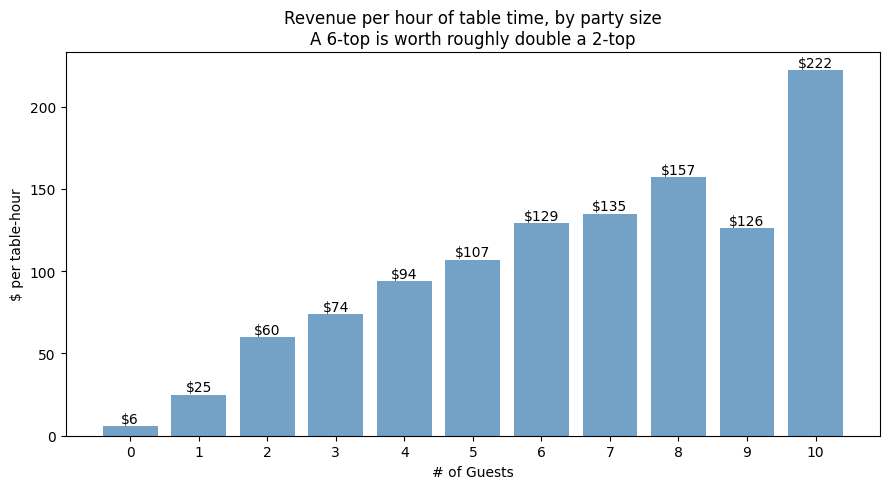

In [26]:
# CORRECTION. An earlier version of this cell claimed E3 was the only table in the building
# seating 5+, and that three quarters of large parties were therefore accommodated ad hoc. That
# was an artifact of the old per-code capacities, which modelled Black Duck as four small tables
# (11 seats) rather than a 6-seat and an 8-seat banquette (14 seats). Both Black Duck banquettes
# seat 5+ by design. The corrected picture is below.
big_parties = res[res['# of Guests'] >= 5].copy()

print(f'Parties of 5+: {len(big_parties)} seatings '
      f'({100 * len(big_parties) / len(res):.1f}% of all seatings) generating '
      f'${big_parties["Amount"].sum():,.0f} '
      f'= {100 * big_parties["Amount"].sum() / res["Amount"].sum():.1f}% of section revenue')

units_5plus = {u: spec['seats'] for u, spec in artemis.SEATING_UNITS.items()
               if spec['seats'] >= 5 and artemis.get_section(spec['tables'][0]) in artemis.RESERVATION_SECTIONS}
print(f'\nUnits seating 5+ without spanning units: {units_5plus}')
print(f'  = {sum(units_5plus.values())} of {sum(artemis.section_seats(s) for s in artemis.RESERVATION_SECTIONS)}'
      ' reservation seats sit in units that can take a party of five or more.')

print('\nWhere large parties actually sat:')
placement = (big_parties.groupby('Seating_Unit')
               .agg(**{'Seatings': ('Amount', 'count'),
                       'Median Guests': ('# of Guests', 'median'),
                       'Revenue ($)': ('Amount', 'sum'),
                       'Fits the unit': ('Likely_Combined_Booking', lambda s: (~s).sum())})
               .sort_values('Seatings', ascending=False))
placement['% fitting'] = (100 * placement['Fits the unit'] / placement['Seatings']).round(0)
print(placement.round(0).to_string())

fits = (~big_parties['Likely_Combined_Booking']).sum()
print(f'\n{fits} of {len(big_parties)} large parties ({100 * fits / len(big_parties):.0f}%) fit'
      ' entirely within a single physical unit.')
print('The floor plan serves this segment far better than the old capacity model suggested.')

fig, ax = plt.subplots(figsize=(9, 5))
sizes = party_econ.index
ax.bar(sizes, party_econ['$ per table-hour'], color='steelblue', alpha=0.75)
for s, v in zip(sizes, party_econ['$ per table-hour']):
    ax.text(s, v + 2, f'${v:.0f}', ha='center', fontsize=10)
ax.set_xlabel('# of Guests')
ax.set_ylabel('$ per table-hour')
ax.set_title('Revenue per hour of table time, by party size\n'
             'A 6-top is worth roughly double a 2-top')
ax.set_xticks(sizes)
plt.tight_layout()
plt.show()

In [27]:
# Is the decline in party count or party size? This matters: fewer parties is a demand problem,
# smaller parties is a mix problem, and they have different fixes.
res_monthly = res.copy()
res_monthly['Month'] = res_monthly['Service_Date'].dt.to_period('M')
trend = res_monthly.groupby('Month').agg(**{
    'Nights': ('Service_Date', 'nunique'),
    'Parties': ('Amount', 'count'),
    'Avg Party Size': ('# of Guests', 'mean'),
    'Revenue': ('Amount', 'sum'),
})
trend['Parties/night'] = (trend['Parties'] / trend['Nights']).round(1)
trend['Revenue/night'] = (trend['Revenue'] / trend['Nights']).round(0)

print('Apr 2025 and Sep 2026 are partial months.')
print(trend[['Nights', 'Parties/night', 'Avg Party Size', 'Revenue/night']].round(2).to_string())
print('\nParties per night is falling; average party size is not. The decline is footfall,')
print('not mix. Decline vs season is answered on the warehouse: analysis/results/trend.md.')

Apr 2025 and Sep 2026 are partial months.
         Nights  Parties/night  Avg Party Size  Revenue/night
Month                                                        
2025-04       4           21.2            2.71         1851.0
2025-05      26           26.0            2.94         3068.0
2025-06      25           23.5            2.99         2978.0
2025-07      26           25.1            3.14         3163.0
2025-08      27           26.0            3.15         3212.0
2025-09      25           22.2            3.11         2834.0
2025-10      27           24.6            3.20         3263.0
2025-11      25           27.5            3.14         3775.0
2025-12      23           25.2            3.18         3784.0
2026-01      25           26.0            2.99         3730.0
2026-02      23           27.9            3.05         3995.0
2026-03      26           23.0            3.24         3335.0
2026-04      26           22.2            3.26         3143.0
2026-05      27           23

## What this section concludes

**Retracted (2026-10-26): "the room never fills; the constraint is unambiguously demand."** That came from counting only the recorded table code (see the correction at the top of this section). Counting every table a party used:

- **The room does fill, on weekends.** 48 fifteen-minute slots on 28 nights had every reservation table occupied (old count: 0); 494 hours of service ran over 75% full. Median utilization while open is 37% overall and 65% on Fri/Sat. The warehouse count, which also knows the three-table and old-layout combinations, finds 148 full slots on 71 nights.
- **Gaps still shrink as the room fills:** 78 min when under a quarter full, 25 min when over three quarters. On quiet nights the gap is missing demand, not slow turning. But 43% of turns now happen in a room over 75% full (it was a small minority under the old count).
- **No individual table is the problem.** Best to worst spans 12 minutes.
- **Faster turning is worth ~$25K/yr** here (~$38K/yr on the warehouse) for hitting the 25-minute reset in a busy room, against ~$116K/yr if every freed minute sold. Earlier figures ("$9K/yr", then "$18K/yr") used the old occupancy, and the $18K also annualized twice.
- Turn gaps are **10.5%** of unsold table time; the rest is tables with no party, overwhelmingly midweek and early or late in the night.

**Party-size steering now has something to work with.** A 6-top earns $129 per table-hour against $60 for a 2-top, for ~26 extra minutes. 4.6% of seatings put a small party at a larger table while the room was over 75% full (old count: 1.3%). It's a weekend-evening rule, not an all-week one.

**Large parties and the floor plan:** 83% of parties of 5+ fit entirely within a single physical unit, and 30 of the 46 reservation seats sit in units that take five or more. There is no layout problem to solve. (An earlier claim that `E3` was the only 5+ unit was an artifact of the old capacity model and stays retracted.)

**The trend:** parties per night are falling while party size holds; the decline-vs-season question is answered on the warehouse (`analysis/results/trend.md`): both.

**Direction this points:** two businesses. Friday and Saturday evenings are capacity-limited, so turning and seating well pay there. Tuesday to Thursday and Sunday are demand-limited, so what matters is hours and bringing people in.

# The Owner's Questions

Taken directly from the operator's own written notes, answered in their words.

1. *"How to seat parties back to back if party is 2/3 guests"*
2. *"Revenue by time (depending on opening)"*
3. *"Value per person per 15 mins"* — already ticked
4. *"Are these priced well? Is this cost justifiable for time slot and party size?"* — the $1,200 / $900 private-event rates
5. *"Should E3 seat 4 when there is no party of 5/6?"*
6. *"Same issue with BD1&2. Should they seat 5s (3+2)?"*
7. *"Bigger tables have longer reservation… need to weight larger parties higher during 15 min intervals?"*

## "Are these priced well?" — the $1,200 / $900 private-event rates

A private event sells a section for three hours. The right benchmark is therefore **what that section would have earned in its best three hours of ordinary service** — because that is what the booking displaces.

Computed from the occupancy timeline: revenue is spread across the 15-minute slots each party occupied, then a rolling 12-slot (3-hour) sum finds each night's best window. Split by day of week, because a Tuesday and a Saturday displace very different amounts.

**Assumption, stated plainly:** the quoted price is treated as total revenue to the bar for that space and time. If the event also drives bar or other-section spend, the deal is better than shown; if the event blocks walk-ins elsewhere, worse. Neither is modelled.

In [28]:
EVENT_PRICES = {'Black Duck': 1200, 'Evangeline': 900}   # 3-hour private-event rates
EVENT_HOURS = 3
SLOTS_PER_BLOCK = EVENT_HOURS * 4

def best_block_per_night(section_df):
    """Each night's best 3-hour revenue window for one section, from the occupancy timeline."""
    section_occ = artemis.build_occupancy(section_df)
    slot_rev = (section_occ.groupby(['Service_Date', 'Service_DOW', 'Slot'])['Slot_Revenue']
                           .sum().reset_index())
    rows = []
    for (date, dow), night in slot_rev.groupby(['Service_Date', 'Service_DOW']):
        series = night.set_index('Slot')['Slot_Revenue']
        # Reindex over the full span so unoccupied slots inside the night count as zero,
        # otherwise a quiet hour would be skipped rather than dragging the window down.
        filled = series.reindex(range(series.index.min(), series.index.max() + 1), fill_value=0.0)
        if len(filled) >= SLOTS_PER_BLOCK:
            rows.append({'Service_Date': date, 'Service_DOW': dow,
                         'Best 3h ($)': filled.rolling(SLOTS_PER_BLOCK).sum().max()})
    return pd.DataFrame(rows)

event_verdicts = {}
for section, price in EVENT_PRICES.items():
    blocks = best_block_per_night(seated[seated['Section'] == section])
    event_verdicts[section] = blocks

    table = (blocks.groupby('Service_DOW')['Best 3h ($)']
                   .agg(**{'Nights': 'count', 'Median': 'median', 'Best ever': 'max'})
                   .reindex(DOW_ORDER).dropna(how='all'))
    table['Event premium'] = price - table['Median']
    table['% nights price wins'] = [
        100 * (blocks.loc[blocks['Service_DOW'] == d, 'Best 3h ($)'] < price).mean()
        for d in table.index]

    print(f'{section} — ${price} for {EVENT_HOURS} hours   ({len(blocks)} nights with enough data)')
    print(table.round(0).to_string())
    print(f'  overall: median best-3h ${blocks["Best 3h ($)"].median():,.0f}, '
          f'best ever ${blocks["Best 3h ($)"].max():,.0f}; '
          f'the price beats {100 * (blocks["Best 3h ($)"] < price).mean():.0f}% of nights')

    # Sanity check: a 3-hour window can never exceed the whole night's section revenue.
    per_night = seated[seated['Section'] == section].groupby('Service_Date')['Amount'].sum()
    assert blocks['Best 3h ($)'].median() <= per_night.median(), 'block exceeds whole night'
    print(f'  cross-check vs whole-night section revenue (median ${per_night.median():,.0f}): OK\n')

Black Duck — $1200 for 3 hours   (320 nights with enough data)
             Nights  Median  Best ever  Event premium  % nights price wins
Service_DOW                                                               
Tuesday          37   371.0      958.0          829.0                100.0
Wednesday        52   420.0      814.0          780.0                100.0
Thursday         52   430.0     1350.0          770.0                 98.0
Friday           73   705.0     1611.0          495.0                 99.0
Saturday         73   725.0     1440.0          475.0                 99.0
Sunday           33   356.0      847.0          844.0                100.0
  overall: median best-3h $549, best ever $1,611; the price beats 99% of nights
  cross-check vs whole-night section revenue (median $724): OK



Evangeline — $900 for 3 hours   (232 nights with enough data)


             Nights  Median  Best ever  Event premium  % nights price wins
Service_DOW                                                               
Tuesday          17   169.0      584.0          731.0                100.0
Wednesday        24   388.0      645.0          512.0                100.0
Thursday         29   411.0      898.0          489.0                100.0
Friday           73   621.0     1004.0          279.0                 96.0
Saturday         73   631.0      953.0          269.0                 97.0
Sunday           16   319.0      781.0          581.0                100.0
  overall: median best-3h $557, best ever $1,004; the price beats 98% of nights


  cross-check vs whole-night section revenue (median $842): OK



In [29]:
# Q: "Should E3 seat 4 when there is no party of 5/6?"
#
# The worry is holding the room's only 5/6-seater for a large party that may not come. The cost
# of seating a 4 there is only real if a 5/6 party then arrives and finds E3 taken -- so measure
# exactly that, rather than reasoning about it.
e3 = res[res['Table'] == 'E3']
print(f'E3: {len(e3)} seatings — {(e3["# of Guests"] >= 5).sum()} parties of 5+, '
      f'{(e3["# of Guests"] <= 4).sum()} of 4 or fewer\n')

# Every slot in which E3 was held by a party of 4 or fewer.
small_at_e3 = set()
for r in e3[e3['# of Guests'] <= 4].itertuples():
    start = int((r.Opened_DT - r.Service_Date).total_seconds() // 900)
    end = int((r.Paid_DT - r.Service_Date).total_seconds() // 900)
    small_at_e3.update((r.Service_Date, s) for s in range(start, end + 1))

five_six = res[res['# of Guests'].between(5, 6)].copy()
five_six['Slot'] = ((five_six['Opened_DT'] - five_six['Service_Date']).dt.total_seconds() // 900).astype(int)
collided = [(d, s) in small_at_e3 for d, s in zip(five_six['Service_Date'], five_six['Slot'])]

print(f'Parties of 5-6 across the reservation sections: {len(five_six)}')
print(f'  arrived while E3 was held by a party of <=4: {sum(collided)} '
      f'({100 * np.mean(collided):.1f}%)')
print(f'  = once every {res["Service_Date"].nunique() / max(sum(collided), 1):.1f} nights')
print(f'  and all of them were still seated — ${five_six[collided]["Amount"].sum():,.0f} in revenue,')
print('    since Black Duck\'s two banquettes also take parties of five and six.')
print(f'\nVERDICT: yes, seat 4s at E3. The conflict arises about once every '
      f'{res["Service_Date"].nunique() / max(sum(collided), 1):.1f} nights, and even')
print('then the party is accommodated elsewhere. Holding the unit empty costs more than it saves,')
print('except perhaps on a full weekend evening, when a turned-away party would not show in Toast.')

E3: 519 seatings — 225 parties of 5+, 294 of 4 or fewer

Parties of 5-6 across the reservation sections: 1117
  arrived while E3 was held by a party of <=4: 227 (20.3%)
  = once every 1.9 nights
  and all of them were still seated — $46,607 in revenue,
    since Black Duck's two banquettes also take parties of five and six.

VERDICT: yes, seat 4s at E3. The conflict arises about once every 1.9 nights, and even
then the party is accommodated elsewhere. Holding the unit empty costs more than it saves,
except perhaps on a full weekend evening, when a turned-away party would not show in Toast.


In [30]:
# Q: "Same issue with BD1&2. Should they seat 5s (3+2)?"
#
# The unit model answers this directly: BD1+BD2 is one 6-seat banquette, so a party of five fits
# inside it with nothing pushed together. The data confirms it is already happening.
bd6 = res[res['Seating_Unit'] == 'BD 6-top banquette']
fives = bd6[bd6['# of Guests'] == 5]
anchors = {code: int(n) for code, n in fives['Table'].value_counts().items()}

print(f'BD1+BD2 (one 6-seat banquette): {len(bd6)} seatings')
print(f'  parties of exactly 5 already seated there: {len(fives)} (anchored on {anchors})')
print(f'  every one of them fits inside the unit: {bool((~fives["Likely_Combined_Booking"]).all())}')

if len(fives):
    five_tpcpm = fives['Amount'] / (fives['Duration'] / 15)
    print(f'  median stay {fives["Duration"].median():.0f} min, median check ${fives["Amount"].median():.0f}, '
          f'${4 * np.exp(np.log(five_tpcpm).mean()):.0f} per table-hour')

# How much slack do the Black Duck banquettes actually have at peak?
print('\nBlack Duck occupancy, 7-11pm:')
for unit in ['BD 6-top banquette', 'BD 8-top banquette']:
    unit_tables = artemis.SEATING_UNITS[unit]['tables']
    busy = occ[occ['Table'].isin(unit_tables)][['Service_Date', 'Slot']].drop_duplicates()
    all_slots = occ[['Service_Date', 'Slot']].drop_duplicates()
    merged = all_slots.merge(busy.assign(Busy=True), on=['Service_Date', 'Slot'], how='left')
    peak_slots = merged[merged['Slot'].between(76, 92)]        # 19:00-23:00
    print(f'  {unit}: occupied {100 * peak_slots["Busy"].notna().mean():.0f}% of peak slots')

print('\nVERDICT: yes — and it is already standard practice. BD1+BD2 is a single 6-seat banquette,')
print('so a 5 needs no combining at all, and those parties earn well. Each banquette is free for')
print('roughly half of the 7-11pm slots across the week, so midweek there is no scarcity to ration;')
print('on a full Fri/Sat evening, giving it to a 5 or 6 rather than a 2 is the better use.')

BD1+BD2 (one 6-seat banquette): 901 seatings
  parties of exactly 5 already seated there: 115 (anchored on {'BD2': 63, 'BD1': 52})
  every one of them fits inside the unit: True
  median stay 94 min, median check $169, $104 per table-hour

Black Duck occupancy, 7-11pm:
  BD 6-top banquette: occupied 57% of peak slots
  BD 8-top banquette: occupied 44% of peak slots

VERDICT: yes — and it is already standard practice. BD1+BD2 is a single 6-seat banquette,
so a 5 needs no combining at all, and those parties earn well. Each banquette is free for
roughly half of the 7-11pm slots across the week, so midweek there is no scarcity to ration;
on a full Fri/Sat evening, giving it to a 5 or 6 rather than a 2 is the better use.


In [31]:
# Q: "Bigger tables have longer reservation: party of 6+ gets 2 hours, party of 2 has 1.5.
#     Need to weight larger parties higher during 15 min intervals?"
#
# Two separate things here. First: is the allowance being observed at all?
ALLOWANCE = {2: 90, 3: 90, 4: 105, 5: 120, 6: 120, 7: 120, 8: 120}   # minutes, per the notes

policy = []
for size, allowed in ALLOWANCE.items():
    party = res[res['# of Guests'] == size]
    if len(party) < 10:
        continue
    over = party['Duration'] > allowed
    policy.append({'Party size': size, 'Allowed (min)': allowed, 'Orders': len(party),
                   'Median actual': round(party['Duration'].median()),
                   '% over allowance': round(100 * over.mean()),
                   'Median overstay': round(party.loc[over, 'Duration'].median() - allowed)})
policy = pd.DataFrame(policy)
print('Reservation allowance vs what actually happens:')
print(policy.to_string(index=False))

# Second: does an overstay ever cost anything? Only if the room was full when it happened.
over_rows = res[res['# of Guests'].map(ALLOWANCE).notna()].copy()
over_rows['Allowed'] = over_rows['# of Guests'].map(ALLOWANCE)
over_rows = over_rows[over_rows['Duration'] > over_rows['Allowed']].copy()
over_rows['Slot'] = ((over_rows['Paid_DT'] - over_rows['Service_Date']).dt.total_seconds() // 900).astype(int)
over_rows = over_rows.merge(room[['Service_Date', 'Slot', 'Room %']], on=['Service_Date', 'Slot'], how='left')
over_rows['Room %'] = over_rows['Room %'].fillna(0)

print(f'\nSeatings that ran past their allowance: {len(over_rows)}')
print(f'  of which the room was >75% full at the time: {(over_rows["Room %"] > 75).sum()} '
      f'({100 * (over_rows["Room %"] > 75).mean():.1f}%)')
print(f'  median room fullness during an overstay: {over_rows["Room %"].median():.0f}%')

busy_share = 100 * (over_rows['Room %'] > 75).mean()
print('\nVERDICT: the allowance is not being enforced — a quarter to a half of every party size')
print(f'runs past it. The room was over 3/4 full for {busy_share:.0f}% of those overstays, nearly all')
print('on Fri/Sat evenings: those are worth a nudge, the rest cost nothing. On weighting larger')
print('parties higher in the 15-minute')
print('intervals: TPCPM already does exactly that, since it divides revenue by time occupied.')
print('A 6-top earns about double a 2-top per table-hour and stays only ~26 minutes longer.')

Reservation allowance vs what actually happens:
 Party size  Allowed (min)  Orders  Median actual  % over allowance  Median overstay
          2             90    5466             85                44               22
          3             90    1160             92                53               25
          4            105    2105             97                41               20
          5            120     591             98                28               20
          6            120     526            111                39               21
          7            120     112            101                31               28
          8            120     189            116                46               21

Seatings that ran past their allowance: 4355
  of which the room was >75% full at the time: 1216 (27.9%)
  median room fullness during an overstay: 59%

VERDICT: the allowance is not being enforced — a quarter to a half of every party size
runs past it. The room was over

## Answers, in the order they were asked

**1. "How to seat parties back to back if party is 2/3 guests"** — *Worth it on Friday and Saturday evenings.* Tables already turn in about 25 minutes when the room is busy; the 31-minute median is inflated by quiet nights where nobody is waiting. Hitting the busy-room standard whenever the room is over 75% full is worth roughly **$25K a year** here (~$38K on the warehouse, nearly 90% of it Fri/Sat), assuming a party is waiting then. Midweek, not worth the effort.

**2. "Revenue by time (depending on opening)"** — *Answered* in the next section. Utilization while open: Tuesday **22%**, Friday **53%**, Saturday **50%**; 73–102 unused table-hours a night, mostly at the edges of the night.

**3. "Value per person per 15 mins"** — *Done.* Per table is the more useful cut: a 2-top returns **$60 per table-hour**, a 6-top **$129**, for only ~26 minutes more occupancy.

**4. "Are these priced well?"** — *Yes, both, comfortably.* $1,200 for Black Duck beats what the space earns in its best three hours on **99% of nights** (median $549). $900 for Evangeline beats 98% (median $557). Two refinements:
   - **The midweek premium is far larger than the weekend one.** An event is worth ~$830 above normal trade on a Tuesday but only ~$475 on a Saturday. Discounting midweek is close to free money.
   - **The weekend ceiling is exposed.** Black Duck's best-ever 3-hour block was $1,611, above the $1,200 price.

**5. "Should E3 seat 4 when there is no party of 5/6?"** — *Yes.* A 5-or-6 party arrives to find E3 held by a smaller one about once every two nights over the whole period (once every four since E3 became the large table in Nov 2025, the figure the owner report uses), and every one was still seated. On a full weekend evening a turned-away party wouldn't show in Toast, so holding E3 for a booked 5/6 can make sense then.

**6. "Same issue with BD1&2. Should they seat 5s (3+2)?"** — *Yes, and it already happens.* `BD1`+`BD2` is a single **6-seat banquette**: 115 parties of five, **$104 per table-hour**.

**7. "Need to weight larger parties higher during 15 min intervals?"** — *Already handled; the allowance matters only on busy nights.* TPCPM divides revenue by time occupied, which is exactly that weighting. **28–53% of each party size runs past the allowance**, and the room was over 75% full for **28%** of those overstays, nearly all Fri/Sat evenings.

---

**The thread running through all seven:** it depends on the night. Friday and Saturday evenings are close to full, and turning, seating and allowances matter there. The rest of the week, the constraint is filling seats.

# Revenue by Time of Day

The owner's second question. Midweek the constraint is demand, and even on Friday and Saturday the
room is quiet early and late, so the question here is *when* the room is empty, and whether those
hours are worth keeping the lights on for.

Two external factors get tested here as well: weather (Ronkonkoma, NY, via Open-Meteo) and
holidays. The weather section carries an important caveat about what this window can and
cannot support — see the seasonality analysis at the end.

In [32]:
import weather

# One row per trading night, across every seated section including the bar -- this is the
# business-level series, not the reservation-sections-only view used earlier.
nightly = (seated[seated['Order_Type'] == 'Seated']
           .groupby(['Service_Date', 'Service_DOW'])
           .agg(**{'Revenue': ('Amount', 'sum'),
                   'Parties': ('Amount', 'count'),
                   'Guests': ('# of Guests', 'sum')})
           .reset_index())

nightly = weather.add_weather(nightly)     # cached after the first run; no network needed
nightly = weather.add_holidays(nightly)

print(f'{len(nightly)} trading nights, weather matched on '
      f'{nightly["Temp_High_F"].notna().sum()}')
nightly.head()

Weather served entirely from cache (523 days, no network call).
437 trading nights, weather matched on 437


,Service_Date,Service_DOW,Revenue,Parties,Guests,Temp_High_F,Temp_Low_F,Precip_In,Wind_Max_Mph,Holiday,Is_Holiday
0,2025-04-25,Friday,2007.85,32,80,66.8,53.0,0.008,13.9,NaN,False
1,2025-04-26,Saturday,2646.93,39,103,64.0,55.7,0.618,21.8,NaN,False
2,2025-04-29,Tuesday,2926.95,33,79,64.0,51.2,0.000,24.6,NaN,False
3,2025-04-30,Wednesday,2865.30,30,72,69.6,57.0,0.000,19.6,NaN,False
4,2025-05-01,Thursday,1647.96,17,47,64.3,46.6,0.000,14.3,NaN,False


## The shape of each night

Revenue is spread across the 15-minute slots a party occupied, then summed by clock hour and
averaged over the number of that weekday in the data. So this reads as "a typical Tuesday earns
this much between 8 and 9pm".

In [33]:
# Hours past midnight are kept as 24/25 rather than wrapping to 0/1, so a Friday running to
# 1:30am reads as one continuous night rather than restarting at the left edge of the chart.
all_occ = artemis.build_occupancy(seated[seated['Order_Type'] == 'Seated'])
all_occ['Hour'] = (all_occ['Clock_Minutes'] // 60).astype(int)
nights_per_dow = seated.groupby('Service_DOW')['Service_Date'].nunique()

hourly = all_occ.groupby(['Service_DOW', 'Hour'])['Slot_Revenue'].sum().reset_index()
hourly['Per Night'] = hourly['Slot_Revenue'] / hourly['Service_DOW'].map(nights_per_dow)

shape = (hourly.pivot_table(index='Hour', columns='Service_DOW', values='Per Night')
               .reindex(columns=DOW_ORDER).fillna(0))
shape = shape[(shape.index >= 15) & (shape.index <= 26)]
shape.index = [f'{h % 24:02d}:00' + (' +1' if h >= 24 else '') for h in shape.index]

# Reconciliation. The occupancy timeline drops seatings longer than MAX_PLAUSIBLE_SEATING_MINUTES
# (6 hours) because a check left open overnight would otherwise mark a table busy for days, so
# the hourly split lands slightly under the recorded total. Worth stating rather than hiding.
split_total = hourly['Slot_Revenue'].sum()
actual_total = seated.loc[seated['Order_Type'] == 'Seated', 'Amount'].sum()
dropped = seated[(seated['Order_Type'] == 'Seated')
                 & (seated['Duration'] > artemis.MAX_PLAUSIBLE_SEATING_MINUTES)]
print(f'hour-by-hour total ${split_total:,.0f} vs recorded ${actual_total:,.0f} '
      f'({100 * (actual_total - split_total) / actual_total:.2f}% short)')
print(f'  accounted for by {len(dropped)} seating(s) over '
      f'{artemis.MAX_PLAUSIBLE_SEATING_MINUTES / 60:.0f}h, worth ${dropped["Amount"].sum():,.0f} '
      '-- checks left open, not real occupancy.\n')

print('Revenue earned per night, by clock hour:')
shape.round(0)

hour-by-hour total $1,918,303 vs recorded $1,932,644 (0.74% short)
  accounted for by 157 seating(s) over 6h, worth $14,340 -- checks left open, not real occupancy.

Revenue earned per night, by clock hour:


Service_DOW,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
15:00,1.0,0.0,1.0,2.0,2.0,53.0
16:00,64.0,80.0,93.0,164.0,344.0,246.0
17:00,171.0,210.0,205.0,544.0,780.0,373.0
18:00,296.0,355.0,388.0,883.0,919.0,373.0
19:00,416.0,510.0,587.0,1073.0,1060.0,444.0
20:00,478.0,570.0,665.0,1087.0,1068.0,428.0
21:00,446.0,515.0,610.0,1007.0,1019.0,334.0
22:00,341.0,411.0,489.0,954.0,926.0,209.0
23:00,193.0,237.0,324.0,839.0,835.0,107.0
00:00 +1,25.0,40.0,65.0,527.0,581.0,13.0


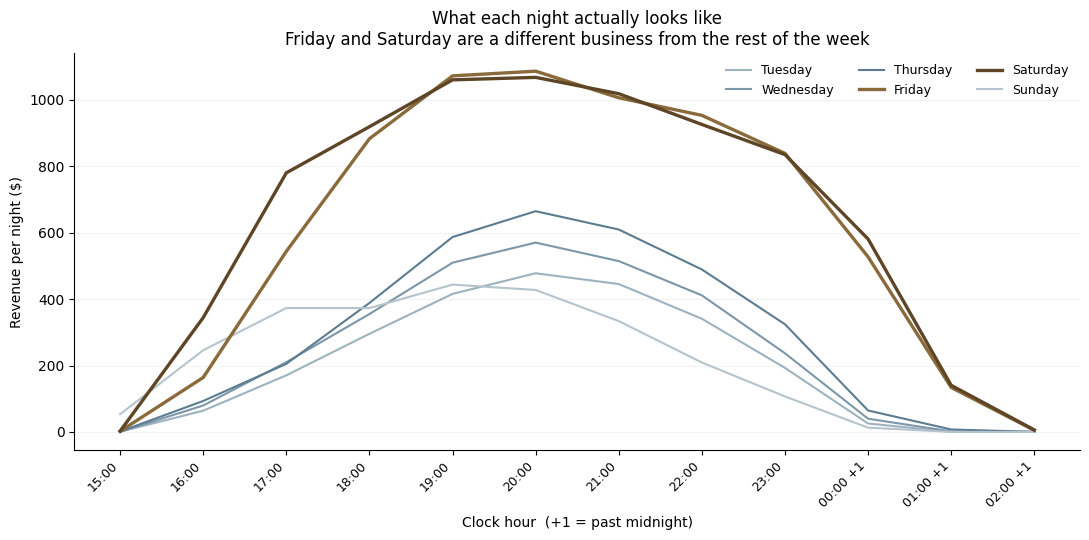

In [34]:
fig, ax = plt.subplots(figsize=(11, 5.5))

palette = {'Tuesday': '#9CB2BF', 'Wednesday': '#7C97A8', 'Thursday': '#5B7C91',
           'Friday': '#8A6A3B', 'Saturday': '#5E4526', 'Sunday': '#B5C4CC'}
positions = range(len(shape.index))

for day in DOW_ORDER:
    weekend = day in ('Friday', 'Saturday')
    ax.plot(positions, shape[day].values,
            label=day, color=palette[day],
            linewidth=2.4 if weekend else 1.5,
            zorder=3 if weekend else 2)

ax.set_xticks(list(positions))
ax.set_xticklabels(shape.index, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Revenue per night ($)')
ax.set_xlabel('Clock hour  (+1 = past midnight)')
ax.set_title('What each night actually looks like\n'
             'Friday and Saturday are a different business from the rest of the week')
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.grid(axis='y', alpha=0.15)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Should the hours change?

Deliberately framed as a break-even rather than a recommendation, because the answer depends on
a number that isn't in this data: what an hour of being open actually costs in wages and
overhead.

So the table below reports what each marginal hour *earns*. An hour is worth keeping if it
brings in more than it costs to staff — a comparison the operator can make immediately with
their own figure, and one that doesn't require me to guess at it.

In [35]:
# The decision only ever sits at the edges of the night -- nobody closes at 8pm. So the
# opening and closing hours are what get costed.
edges = shape.loc[['16:00', '17:00', '23:00', '00:00 +1', '01:00 +1']].T
edges.columns = ['Opens 4pm', 'Opens 5pm', '11pm hour', 'Midnight hour', '1am hour']
# Whole-night total comes from the unclipped hourly data, not `shape` -- `shape` is
# trimmed to 15:00-26:00 for the chart, which would drop ~$900 of early-afternoon
# seatings across the six months.
edges['Whole night'] = (hourly.groupby('Service_DOW')['Slot_Revenue'].sum()
                        / nights_per_dow)
edges = edges.reindex(DOW_ORDER)

print('What each marginal hour earns, per night:')
print(edges.round(0).to_string())

print('\nShare of the night earned in each edge window:')
whole = hourly.groupby('Service_DOW')['Slot_Revenue'].sum() / nights_per_dow
share = pd.DataFrame({
    '4-6pm %': 100 * shape.loc[['16:00', '17:00']].sum() / whole,
    'after midnight %': 100 * shape.loc[['00:00 +1', '01:00 +1', '02:00 +1']].sum() / whole,
}).reindex(DOW_ORDER)
print(share.round(1).to_string())

print("""
READING THIS
  Opening at 4pm earns $46 on a Tuesday and $77 on a Thursday. One bartender for that hour
  costs more than that, so those hours are very likely sold at a loss. Opening at 5pm on
  Tue/Wed/Thu is worth trialling.

  Closing: Tuesday's midnight hour earns $20 and Wednesday's $42 -- effectively nothing.
  Friday and Saturday earn $494 and $612 in the same hour and should absolutely stay open.

  Sunday is a different business from the rest of the week: a quarter of its revenue arrives
  between 4 and 6pm, and it is finished by 11pm. It should open earlier and close earlier.""")

What each marginal hour earns, per night:
             Opens 4pm  Opens 5pm  11pm hour  Midnight hour  1am hour  Whole night
Service_DOW                                                                       
Tuesday           64.0      171.0      193.0           25.0       0.0       2430.0
Wednesday         80.0      210.0      237.0           40.0       2.0       2930.0
Thursday          93.0      205.0      324.0           65.0       7.0       3436.0
Friday           164.0      544.0      839.0          527.0     134.0       7218.0
Saturday         344.0      780.0      835.0          581.0     141.0       7685.0
Sunday           246.0      373.0      107.0           13.0       0.0       2608.0

Share of the night earned in each edge window:
             4-6pm %  after midnight %
Service_DOW                           
Tuesday          9.7               1.1
Wednesday        9.9               1.4
Thursday         8.7               2.1
Friday           9.8               9.2
Saturday    

## Weather, holidays, and the decline

Now the external factors. This is where the analysis has to be careful, because the most
striking correlation in the dataset is also the least trustworthy.

In [36]:
weekend = nightly[nightly['Service_DOW'].isin(['Friday', 'Saturday'])]

print('Correlation of nightly revenue with weather:')
print(f'{"":22} {"all nights":>12} {"Fri/Sat only":>14}')
for col, label in [('Temp_High_F', 'daytime high (F)'),
                   ('Precip_In', 'precipitation (in)'),
                   ('Wind_Max_Mph', 'max wind (mph)')]:
    print(f'  {label:20} {nightly["Revenue"].corr(nightly[col]):>+12.3f} '
          f'{weekend["Revenue"].corr(weekend[col]):>+14.3f}')
print('\n  (Fri/Sat is the cleaner read -- pooling days of week mixes a huge Saturday effect')
print('   into every correlation.)')

# Rain, tested directly rather than through a correlation, since it is nearly binary.
wet = weekend['Precip_In'] > 0.05
print(f'\nRain on Fri/Sat: wet nights ${weekend.loc[wet, "Revenue"].mean():,.0f} '
      f'(n={wet.sum()}) vs dry ${weekend.loc[~wet, "Revenue"].mean():,.0f} (n={(~wet).sum()})')
print('  -> no meaningful effect. Rain is not the weather variable that matters here.')

# Holidays. Almost every one rests on a single night, so these are anecdotes, not estimates.
hol = nightly[nightly['Is_Holiday']].copy()
baseline = nightly.groupby('Service_DOW')['Revenue'].median()
hol['Typical'] = hol['Service_DOW'].map(baseline)
hol['vs typical'] = hol['Revenue'] - hol['Typical']
hol['Date'] = hol['Service_Date'].dt.strftime('%d %b')
print('\nHolidays falling on a trading night (n=1 each -- read as anecdote):')
print(hol[['Date', 'Service_DOW', 'Holiday', 'Revenue', 'Typical', 'vs typical']]
      .round({'Revenue': 0, 'Typical': 0, 'vs typical': 0}).to_string(index=False))

missing_holidays = [f'{name} ({pd.Timestamp(d):%a %d %b})' for d, name in weather.US_HOLIDAYS.items()
                    if pd.Timestamp(d) not in set(nightly['Service_Date'])]
print('\nHolidays with no trading night at all:')
for h in missing_holidays:
    print(f'  {h}')
print('\n  Most are Mondays, when the bar is closed anyway. July 4th is not --')
print('  it is the ONLY dark Saturday in the whole six months.')

Correlation of nightly revenue with weather:
                         all nights   Fri/Sat only
  daytime high (F)           -0.164         -0.475
  precipitation (in)         -0.037         -0.040
  max wind (mph)             +0.038         +0.121

  (Fri/Sat is the cleaner read -- pooling days of week mixes a huge Saturday effect
   into every correlation.)

Rain on Fri/Sat: wet nights $7,483 (n=46) vs dry $7,546 (n=101)
  -> no meaningful effect. Rain is not the weather variable that matters here.

Holidays falling on a trading night (n=1 each -- read as anecdote):
  Date Service_DOW          Holiday  Revenue  Typical  vs typical
14 Feb    Saturday  Valentine's Day   8971.0   8068.0       903.0
17 Mar     Tuesday St Patrick's Day   1992.0   2406.0      -414.0
10 May      Sunday     Mother's Day   3038.0   2251.0       787.0
21 Jun      Sunday     Father's Day   1566.0   2251.0      -685.0

Holidays with no trading night at all:
  Presidents' Day (Mon 16 Feb)
  Easter Sunday (Sun 05 

## Is the decline real, or is it just summer?

Parties per night fell from about 26 in January/February to about 18 in June/July. That is the
single most consequential number in this analysis, so it deserves a careful answer rather than a
confident one.

**This dataset cannot separate the two explanations.** Below is the demonstration, not an
assertion — because "we don't know" is only useful if it comes with the reason and the remedy.

In [37]:
nightly['Week'] = (nightly['Service_Date'] - nightly['Service_Date'].min()).dt.days / 7

def r2(design, y):
    """Fit by least squares, return coefficients and R-squared."""
    design = design.dropna()
    target = y.loc[design.index]
    beta, *_ = np.linalg.lstsq(design.values, target.values, rcond=None)
    resid = target.values - design.values @ beta
    return (dict(zip(design.columns, beta)),
            1 - (resid ** 2).sum() / ((target - target.mean()) ** 2).sum())

base = pd.get_dummies(nightly['Service_DOW'], drop_first=True).astype(float)
base['const'] = 1.0

_, r2_time = r2(base.assign(week=nightly['Week']), nightly['Revenue'])
_, r2_temp = r2(base.assign(temp=nightly['Temp_High_F']), nightly['Revenue'])
coefs_both, r2_both = r2(base.assign(week=nightly['Week'], temp=nightly['Temp_High_F']),
                         nightly['Revenue'])
coefs_time, _ = r2(base.assign(week=nightly['Week']), nightly['Revenue'])

print('THE PROBLEM')
print(f'  correlation between elapsed time and temperature: '
      f'r = {nightly["Week"].corr(nightly["Temp_High_F"]):+.3f}')
print('  Over a window running January to July, "time passing" and "weather warming"')
print('  are very nearly the same variable.\n')

print('Each explains the takings about equally well, and neither adds to the other:')
print(f'  time only          R2 = {r2_time:.3f}')
print(f'  temperature only   R2 = {r2_temp:.3f}')
print(f'  both together      R2 = {r2_both:.3f}')
print(f'    adding temperature to the time model:  {r2_both - r2_time:+.3f}')
print(f'    adding time to the temperature model:  {r2_both - r2_temp:+.3f}')

print('\nTHE DISCRIMINATING TEST')
print('  Within a single month, time barely moves but weather still varies. If heat really')
print('  drives takings down, hot nights should underperform within their own month.')
fs = nightly[nightly['Service_DOW'].isin(['Friday', 'Saturday'])].copy()
fs['Month'] = fs['Service_Date'].dt.to_period('M')
fs['rev_dm'] = fs['Revenue'] - fs.groupby('Month')['Revenue'].transform('mean')
fs['temp_dm'] = fs['Temp_High_F'] - fs.groupby('Month')['Temp_High_F'].transform('mean')
per_month = (fs.groupby('Month')
               .apply(lambda g: g['Revenue'].corr(g['Temp_High_F']) if len(g) >= 6 else np.nan,
                      include_groups=False)
               .dropna().round(2))
print(f'\n  pooled within-month correlation: r = {fs["rev_dm"].corr(fs["temp_dm"]):+.3f} (n={len(fs)})')
print('  by month: ' + ', '.join(f'{m.strftime("%b")} {v:+.2f}' for m, v in per_month.items()))
print('  -> weak, and it flips sign between months on 6-10 nights each. That is noise,')
print('     not a settled answer.')

print('\nTHE HONEST BOUND')
print(f'  If the whole move is seasonal:  the business is flat.')
print(f'  If none of it is:               it is losing ${abs(coefs_time["week"]):,.0f} per night, '
      f'per week elapsed.')
print(f'  Splitting the difference is not a finding -- it is an artifact of which variable')
print(f'  the model happens to favour.')

print('\nWHAT WOULD SETTLE IT')
print('  The same calendar months from last year, exported from Toast. Over a full year')
print('  temperature cycles back down while elapsed time keeps moving, which breaks the')
print('  overlap. It is an existing report on a system we already have access to -- no new')
print('  permission, no new instrumentation, and it answers a bigger question than anything')
print('  else on this list.')

THE PROBLEM
  correlation between elapsed time and temperature: r = +0.014
  Over a window running January to July, "time passing" and "weather warming"
  are very nearly the same variable.

Each explains the takings about equally well, and neither adds to the other:
  time only          R2 = 0.778
  temperature only   R2 = 0.797
  both together      R2 = 0.798
    adding temperature to the time model:  +0.020
    adding time to the temperature model:  +0.001

THE DISCRIMINATING TEST
  Within a single month, time barely moves but weather still varies. If heat really
  drives takings down, hot nights should underperform within their own month.

  pooled within-month correlation: r = -0.092 (n=147)
  by month: May -0.08, Jun -0.69, Jul +0.19, Aug -0.05, Sep +0.37, Oct +0.16, Nov +0.60, Dec +0.12, Jan -0.22, Feb +0.12, Mar -0.12, Apr +0.03, May -0.88, Jun +0.38, Jul -0.36, Aug -0.19, Sep +0.51
  -> weak, and it flips sign between months on 6-10 nights each. That is noise,
     not a settl

## What this section concludes

**The nights are two different businesses.** Friday and Saturday earn $7,300–8,100 and run past
1am. Tuesday through Thursday earn $2,100–3,300 and are effectively finished by 11pm. Sunday is
different again — an afternoon trade, a quarter of it done between 4 and 6pm, dead by 11.

**Three hour changes worth trialling**, each testable against the operator's own labour cost:
- **Open at 5pm rather than 4pm, Tuesday to Thursday.** That hour earns $46–77. One bartender
  costs more.
- **Close at midnight on Tuesday, Wednesday and Sunday.** The midnight hour earns $20, $42 and
  $11 respectively.
- **Leave Friday and Saturday alone.** They earn $494 and $612 in the midnight hour and another
  ~$100 after 1am. That is real trade.

**Rain does not matter.** Wet Friday/Saturdays take $7,592 against $7,903 dry — inside the noise.
Worth knowing so nobody blames the weather forecast for a slow night.

**Temperature appears to matter enormously — and that reading is not safe.** Friday/Saturday
takings correlate −0.72 with the daytime high, which looks like a headline finding. It is
inseparable from the passage of time over this window (r = 0.90 between them), and the
within-month test that would break the tie is too noisy to do so. Quoting the temperature
effect as established would be overclaiming.

**Which leaves the most important question open, and cheaply closeable.** Whether trade is
declining or merely summering cannot be resolved from January-to-July data. The same months
from last year would settle it, and that export already exists in Toast.

**One thing worth asking about:** July 4th was the only Saturday in six months with no trade at
all. Saturdays average $8,146. If that closure was a deliberate call it may well have been the
right one — but it is worth being deliberate about, since it is the single most valuable day of
the week.